# 航空发动机剩余寿命预测与可靠性分析

## 项目简介

本项目基于NASA C-MAPSS FD001航空发动机退化数据集，开展剩余寿命（RUL）预测与可靠性分析。

主要研究内容包括：

- 构建随机森林、XGBoost和LSTM模型，比较其预测性能；
- 模拟传感器噪声、偏移、卡死和数据缺失，评估模型鲁棒性；
- 基于预测区间和模型集成方法开展不确定性分析。

项目从预测精度、故障鲁棒性和不确定性三个方面，评价数据驱动剩余寿命预测模型的可靠性。

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("环境配置成功！")
print("NumPy版本：", np.__version__)
print("Pandas版本：", pd.__version__)
print("Scikit-learn版本：", sklearn.__version__)

环境配置成功！
NumPy版本： 2.4.6
Pandas版本： 3.0.5
Scikit-learn版本： 1.9.0


In [2]:
import sys
print(sys.executable)

D:\aaaa\anaconda\envs\cmapss\python.exe


## 1. 环境配置与项目路径管理

检查Python及相关库的运行环境，统一配置数据集、模型文件和实验结果的存储路径，便于后续实验复现与项目管理。

In [3]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "FD001"
RESULTS_DIR = PROJECT_ROOT / "results"
MODELS_DIR = PROJECT_ROOT / "models"

RESULTS_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)

print("项目路径：", PROJECT_ROOT)

项目路径： D:\cmapss-rul-reliability


## 2. 数据集读取与初步分析

使用NASA C-MAPSS FD001数据集，读取发动机运行数据。

数据包含发动机编号、运行周期、3个工况参数和21个传感器测量值。首先检查数据规模及字段结构，为后续寿命标签构建和特征分析做好准备。

In [4]:
train_path = DATA_DIR / "train_FD001.txt"

In [5]:
train_df = pd.read_csv(
    train_path,
    sep=r"\s+",
    header=None
)

train_df.head()

,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [6]:
print("数据形状：", train_df.shape)

数据形状： (20631, 26)


In [7]:
column_names = (
    ["unit", "cycle"]
    + ["op_setting_1", "op_setting_2", "op_setting_3"]
    + [f"sensor_{i}" for i in range(1, 22)]
)

train_df.columns = column_names

In [8]:
train_df.head()

,unit,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


### 2.1 发动机运行寿命分布分析

统计各台发动机的最大运行周期，并绘制寿命分布直方图，分析不同发动机运行寿命的差异。

In [9]:
engine_life = train_df.groupby("unit")["cycle"].max()

engine_life.head()

unit
1    192
2    287
3    179
4    189
5    269
Name: cycle, dtype: int64

In [10]:
engine_life.describe()

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64

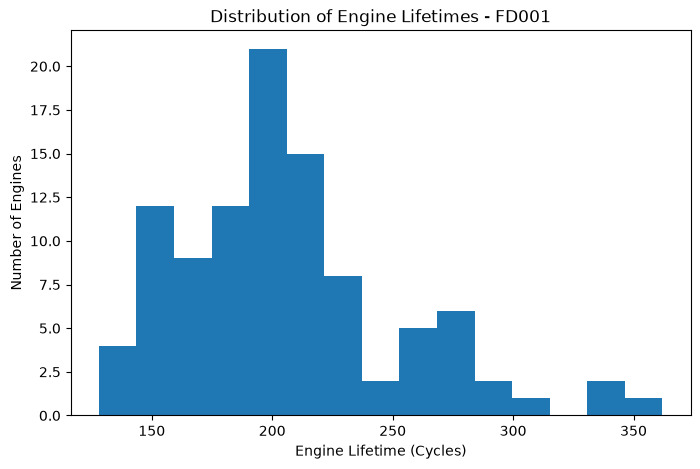

In [11]:
plt.figure(figsize=(8, 5))
plt.hist(engine_life, bins=15)

plt.xlabel("Engine Lifetime (Cycles)")
plt.ylabel("Number of Engines")
plt.title("Distribution of Engine Lifetimes - FD001")

plt.show()

In [12]:
engine_1 = train_df[train_df["unit"] == 1]

print("第1台发动机数据行数：", len(engine_1))
print("第1台发动机最大周期：", engine_1["cycle"].max())

第1台发动机数据行数： 192
第1台发动机最大周期： 192


## 3. 剩余寿命标签构建

对于训练集中具有完整退化过程的发动机，通过最大运行周期与当前运行周期的差值计算剩余寿命：


RUL = C_{\max} - C_t


其中，$C_{\max}$ 表示该发动机的最大运行周期，$C_t$ 表示当前运行周期。

由此构造监督学习模型所需的RUL预测标签。

In [14]:
train_df["max_cycle"] = train_df.groupby("unit")["cycle"].transform("max")

train_df[["unit", "cycle", "max_cycle"]].head(10)

,unit,cycle,max_cycle
0,1,1,192
1,1,2,192
2,1,3,192
3,1,4,192
4,1,5,192
5,1,6,192
6,1,7,192
7,1,8,192
8,1,9,192
9,1,10,192


In [15]:
train_df["RUL"] = train_df["max_cycle"] - train_df["cycle"]

train_df[["unit", "cycle", "max_cycle", "RUL"]].head(10)

,unit,cycle,max_cycle,RUL
0,1,1,192,191
1,1,2,192,190
2,1,3,192,189
3,1,4,192,188
4,1,5,192,187
5,1,6,192,186
6,1,7,192,185
7,1,8,192,184
8,1,9,192,183
9,1,10,192,182


In [16]:
train_df[train_df["unit"] == 1][
    ["unit", "cycle", "max_cycle", "RUL"]
].tail(10)

,unit,cycle,max_cycle,RUL
182,1,183,192,9
183,1,184,192,8
184,1,185,192,7
185,1,186,192,6
186,1,187,192,5
187,1,188,192,4
188,1,189,192,3
189,1,190,192,2
190,1,191,192,1
191,1,192,192,0


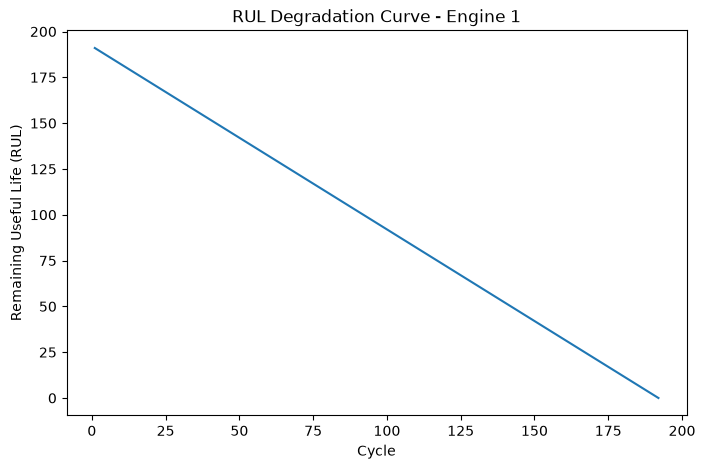

In [17]:
engine_1 = train_df[train_df["unit"] == 1]

plt.figure(figsize=(8, 5))

plt.plot(engine_1["cycle"], engine_1["RUL"])

plt.xlabel("Cycle")
plt.ylabel("Remaining Useful Life (RUL)")
plt.title("RUL Degradation Curve - Engine 1")

plt.show()

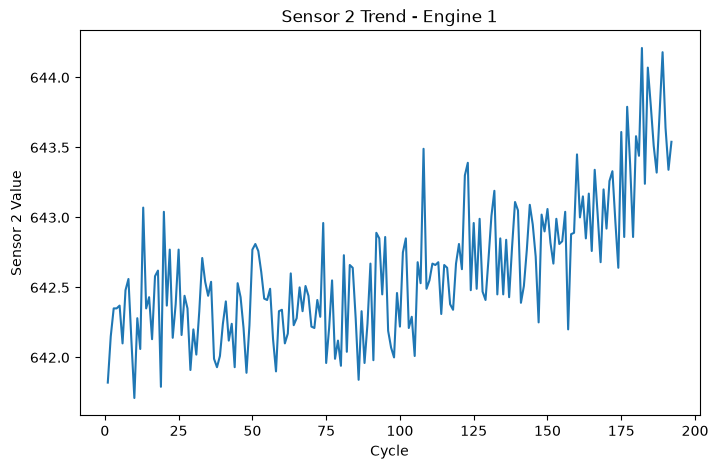

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(engine_1["cycle"], engine_1["sensor_2"])

plt.xlabel("Cycle")
plt.ylabel("Sensor 2 Value")
plt.title("Sensor 2 Trend - Engine 1")

plt.show()

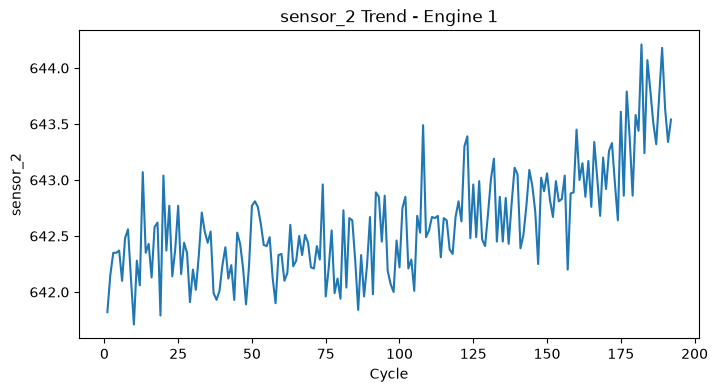

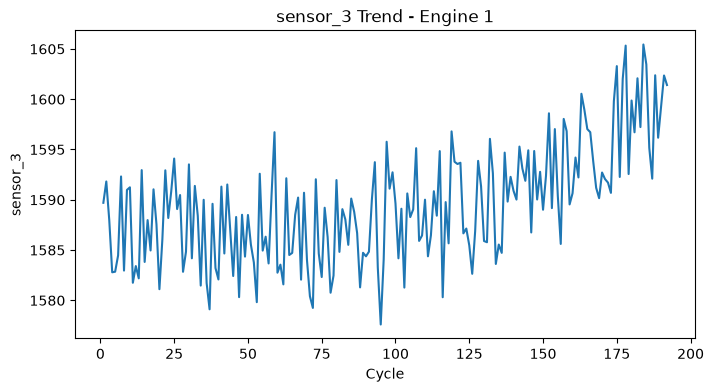

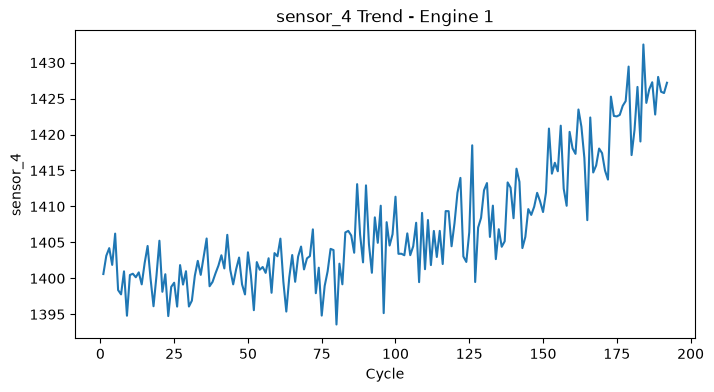

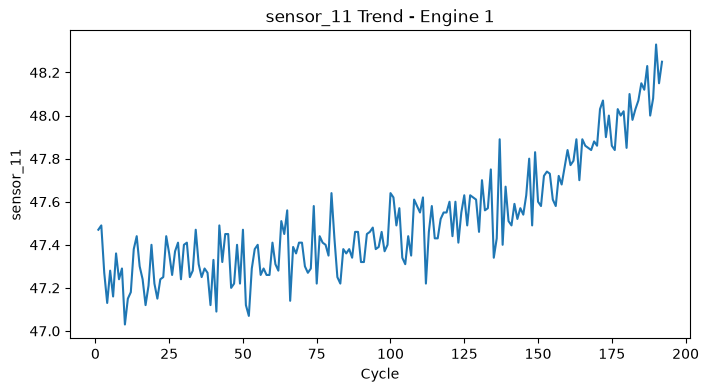

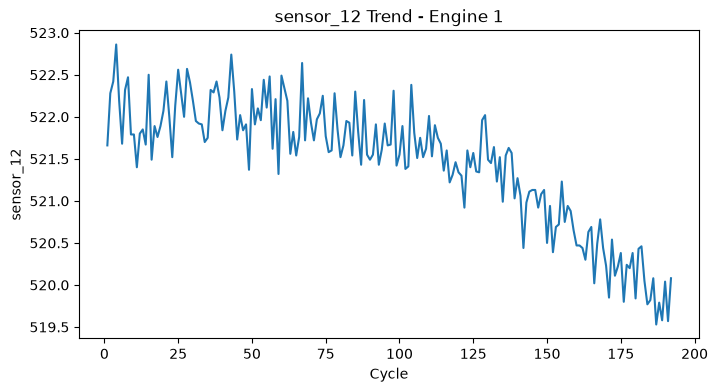

In [19]:
sensors_to_plot = ["sensor_2", "sensor_3", "sensor_4", "sensor_11", "sensor_12"]

for sensor in sensors_to_plot:
    plt.figure(figsize=(8, 4))
    plt.plot(engine_1["cycle"], engine_1[sensor])
    plt.xlabel("Cycle")
    plt.ylabel(sensor)
    plt.title(f"{sensor} Trend - Engine 1")
    plt.show()

## 4. 传感器特征分析与筛选

计算21个传感器的标准差及其与RUL的相关系数，分析传感器数据的变化程度与寿命关联性，为后续特征筛选提供参考。

In [20]:
sensor_cols = [f"sensor_{i}" for i in range(1, 22)]

sensor_std = train_df[sensor_cols].std().sort_values()

sensor_std

sensor_1     0.000000e+00
sensor_10    0.000000e+00
sensor_19    0.000000e+00
sensor_18    0.000000e+00
sensor_16    3.469531e-18
sensor_5     5.329200e-15
sensor_6     1.388985e-03
sensor_15    3.750504e-02
sensor_8     7.098548e-02
sensor_13    7.191892e-02
sensor_21    1.082509e-01
sensor_20    1.807464e-01
sensor_11    2.670874e-01
sensor_2     5.000533e-01
sensor_12    7.375534e-01
sensor_7     8.850923e-01
sensor_17    1.548763e+00
sensor_3     6.131150e+00
sensor_4     9.000605e+00
sensor_14    1.907618e+01
sensor_9     2.208288e+01
dtype: float64

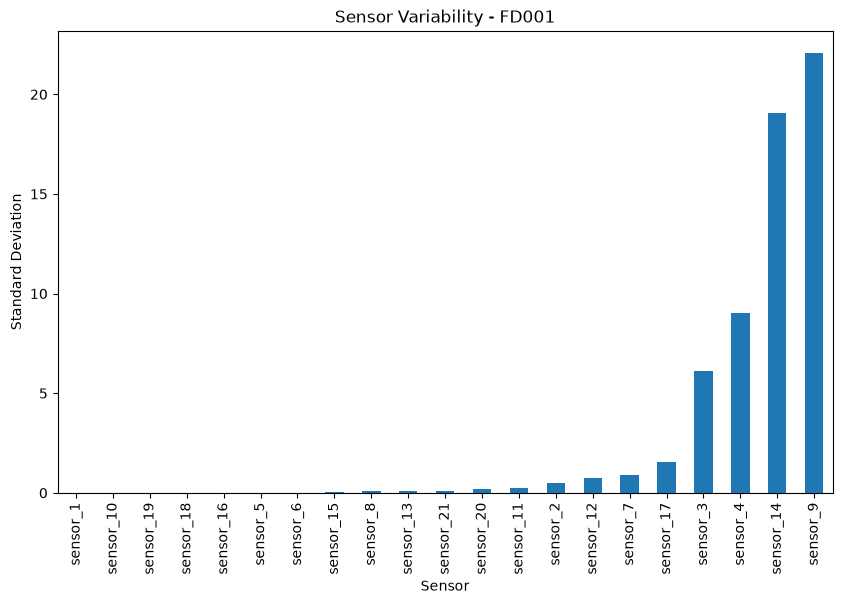

In [21]:
plt.figure(figsize=(10, 6))

sensor_std.plot(kind="bar")

plt.xlabel("Sensor")
plt.ylabel("Standard Deviation")
plt.title("Sensor Variability - FD001")

plt.show()

In [22]:
sensor_corr = train_df[sensor_cols + ["RUL"]].corr()["RUL"].drop("RUL")

sensor_corr = sensor_corr.sort_values()

sensor_corr

sensor_11   -0.696228
sensor_4    -0.678948
sensor_15   -0.642667
sensor_2    -0.606484
sensor_17   -0.606154
sensor_3    -0.584520
sensor_8    -0.563968
sensor_13   -0.562569
sensor_9    -0.390102
sensor_14   -0.306769
sensor_6    -0.128348
sensor_20    0.629428
sensor_21    0.635662
sensor_7     0.657223
sensor_12    0.671983
sensor_1          NaN
sensor_5          NaN
sensor_10         NaN
sensor_16         NaN
sensor_18         NaN
sensor_19         NaN
Name: RUL, dtype: float64

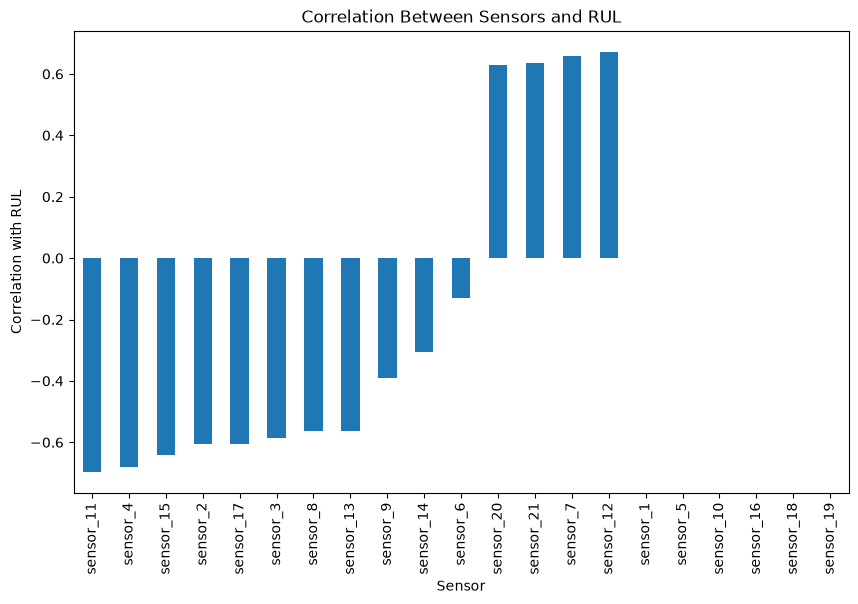

In [23]:
plt.figure(figsize=(10, 6))

sensor_corr.sort_values().plot(kind="bar")

plt.xlabel("Sensor")
plt.ylabel("Correlation with RUL")
plt.title("Correlation Between Sensors and RUL")

plt.show()

### 4.1 低方差传感器筛选

设置标准差阈值为0.01，剔除变化幅度较小的传感器。

当前实验共删除7个低方差传感器，保留14个传感器作为模型输入，以减少冗余特征和计算开销。

In [24]:
low_variance_sensors = sensor_std[sensor_std < 0.01].index.tolist()

print("低方差传感器：")
print(low_variance_sensors)

低方差传感器：
['sensor_1', 'sensor_10', 'sensor_19', 'sensor_18', 'sensor_16', 'sensor_5', 'sensor_6']


In [25]:
selected_sensors = [
    sensor for sensor in sensor_cols
    if sensor not in low_variance_sensors
]

print("保留的传感器数量：", len(selected_sensors))
print(selected_sensors)

保留的传感器数量： 14
['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


In [26]:
X = train_df[selected_sensors]

y = train_df["RUL"]

print("X形状：", X.shape)
print("y形状：", y.shape)

X形状： (20631, 14)
y形状： (20631,)


### 4.2 训练集与验证集划分

按照发动机编号，以8:2的比例划分训练集与验证集，使用固定随机种子42保证划分结果可复现。

同一台发动机的数据不会同时出现在训练集和验证集中，以避免不同运行周期之间的样本交叉。

In [27]:
from sklearn.model_selection import train_test_split

unit_ids = train_df["unit"].unique()

train_units, val_units = train_test_split(
    unit_ids,
    test_size=0.2,
    random_state=42
)

print("训练发动机数量：", len(train_units))
print("验证发动机数量：", len(val_units))

训练发动机数量： 80
验证发动机数量： 20


In [28]:
train_data = train_df[train_df["unit"].isin(train_units)].copy()
val_data = train_df[train_df["unit"].isin(val_units)].copy()

print("训练集数据量：", train_data.shape)
print("验证集数据量：", val_data.shape)

训练集数据量： (16561, 28)
验证集数据量： (4070, 28)


In [29]:
X_train = train_data[selected_sensors]
y_train = train_data["RUL"]

X_val = val_data[selected_sensors]
y_val = val_data["RUL"]

print("X_train：", X_train.shape)
print("y_train：", y_train.shape)

print("X_val：", X_val.shape)
print("y_val：", y_val.shape)

X_train： (16561, 14)
y_train： (16561,)
X_val： (4070, 14)
y_val： (4070,)


In [30]:
overlap = set(train_units) & set(val_units)

print("训练集和验证集重复发动机：", overlap)

训练集和验证集重复发动机： set()


In [31]:
from sklearn import set_config

set_config(display="text")

## 5. 随机森林RUL预测模型

构建包含100棵决策树的随机森林回归模型，学习多维传感器状态与发动机剩余寿命之间的非线性关系。

使用验证集计算平均绝对误差（MAE）和均方根误差（RMSE），并分析各传感器的特征重要性。

In [32]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

In [33]:
rf_model.fit(X_train, y_train);

print("随机森林训练完成")
print("决策树数量：", len(rf_model.estimators_))

随机森林训练完成
决策树数量： 100


In [34]:
y_pred = rf_model.predict(X_val)

print("前10个真实RUL：")
print(y_val.values[:10])

print("\n前10个预测RUL：")
print(np.round(y_pred[:10], 2))

前10个真实RUL：
[191 190 189 188 187 186 185 184 183 182]

前10个预测RUL：
[164.14 178.24 176.31 209.28 161.64 199.68 180.89 190.35 182.8  199.95]


In [35]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(y_val, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_val, y_pred)
)

print("Random Forest MAE：", round(mae, 2))
print("Random Forest RMSE：", round(rmse, 2))

Random Forest MAE： 25.88
Random Forest RMSE： 35.41


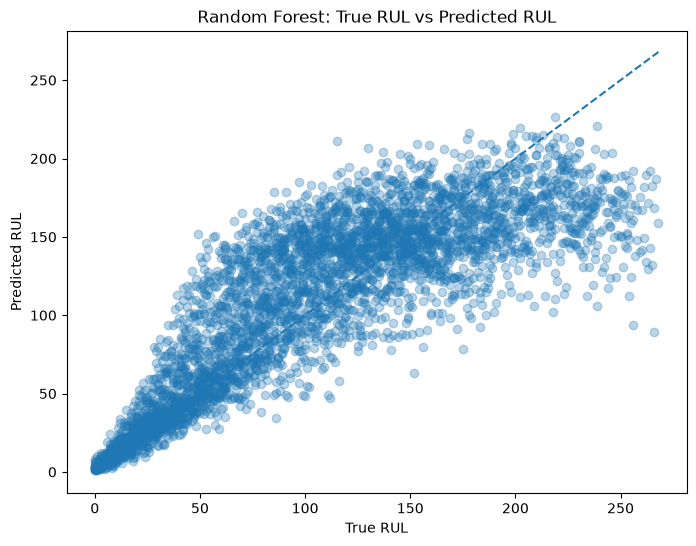

In [36]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_val,
    y_pred,
    alpha=0.3
)

min_rul = min(y_val.min(), y_pred.min())
max_rul = max(y_val.max(), y_pred.max())

plt.plot(
    [min_rul, max_rul],
    [min_rul, max_rul],
    linestyle="--"
)

plt.xlabel("True RUL")
plt.ylabel("Predicted RUL")
plt.title("Random Forest: True RUL vs Predicted RUL")

plt.show()

In [37]:
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=selected_sensors
).sort_values(ascending=False)

feature_importance

sensor_11    0.433971
sensor_9     0.128988
sensor_4     0.080907
sensor_12    0.049602
sensor_14    0.043804
sensor_7     0.040703
sensor_15    0.037418
sensor_21    0.035539
sensor_3     0.033440
sensor_2     0.031374
sensor_20    0.027507
sensor_8     0.023144
sensor_13    0.022828
sensor_17    0.010775
dtype: float64

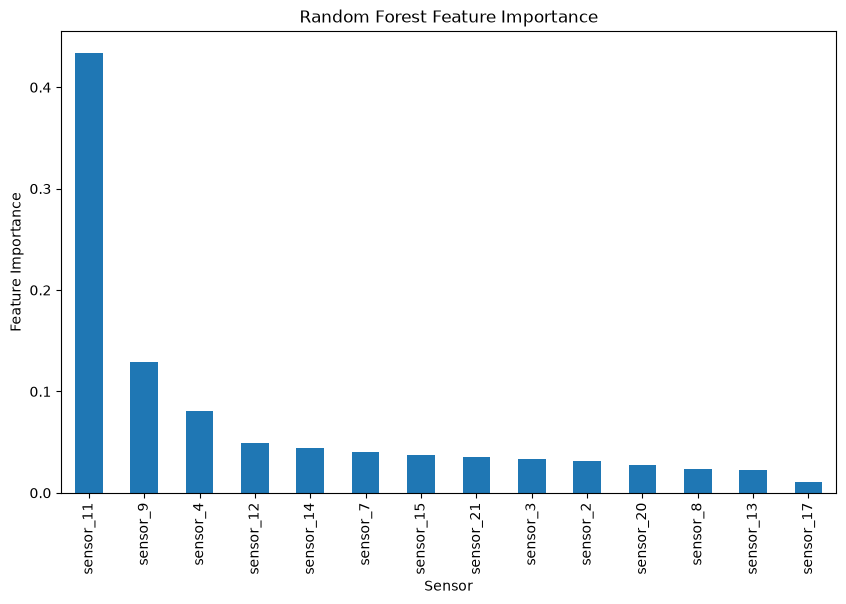

In [38]:
plt.figure(figsize=(10, 6))

feature_importance.plot(kind="bar")

plt.xlabel("Sensor")
plt.ylabel("Feature Importance")
plt.title("Random Forest Feature Importance")

plt.show()

In [39]:
y_pred_rf = rf_model.predict(X_val)

print("前10个真实RUL：")
print(y_val.values[:10])

print("\n前10个预测RUL：")
print(np.round(y_pred_rf[:10], 2))

前10个真实RUL：
[191 190 189 188 187 186 185 184 183 182]

前10个预测RUL：
[164.14 178.24 176.31 209.28 161.64 199.68 180.89 190.35 182.8  199.95]


In [40]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

rf_mae = mean_absolute_error(y_val, y_pred_rf)

rf_rmse = np.sqrt(
    mean_squared_error(y_val, y_pred_rf)
)

print("Random Forest MAE：", round(rf_mae, 2))
print("Random Forest RMSE：", round(rf_rmse, 2))

Random Forest MAE： 25.88
Random Forest RMSE： 35.41


In [41]:
model_results = pd.DataFrame({
    "Model": ["Random Forest"],
    "MAE": [rf_mae],
    "RMSE": [rf_rmse]
})

model_results

,Model,MAE,RMSE
0,Random Forest,25.879071,35.407605


## 6. XGBoost RUL预测模型

采用XGBoost梯度提升树模型进行剩余寿命预测。

模型设置300棵树、最大深度4、学习率0.05，并采用行采样与特征采样控制训练过程。

通过MAE和RMSE评价其预测性能，并与随机森林模型进行对比。

In [42]:
import xgboost as xgb

print("XGBoost版本：", xgb.__version__)

XGBoost版本： 3.2.0


In [43]:
%pip install xgboost

Looking in indexes: https://mirrors.tuna.tsinghua.edu.cn/pypi/web/simple
Note: you may need to restart the kernel to use updated packages.


In [45]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

In [46]:
xgb_model.fit(X_train, y_train)

print("XGBoost训练完成")

XGBoost训练完成


In [47]:
y_pred_xgb = xgb_model.predict(X_val)

print("前10个真实RUL：")
print(y_val.values[:10])

print("\n前10个XGBoost预测RUL：")
print(np.round(y_pred_xgb[:10], 2))

前10个真实RUL：
[191 190 189 188 187 186 185 184 183 182]

前10个XGBoost预测RUL：
[178.43 171.49 178.97 185.23 177.22 186.59 169.01 185.71 188.54 180.76]


In [48]:
xgb_mae = mean_absolute_error(y_val, y_pred_xgb)

xgb_rmse = np.sqrt(
    mean_squared_error(y_val, y_pred_xgb)
)

print("XGBoost MAE：", round(xgb_mae, 2))
print("XGBoost RMSE：", round(xgb_rmse, 2))

XGBoost MAE： 25.71
XGBoost RMSE： 35.22


In [49]:
new_result = pd.DataFrame({
    "Model": ["XGBoost"],
    "MAE": [xgb_mae],
    "RMSE": [xgb_rmse]
})

model_results = pd.concat(
    [model_results, new_result],
    ignore_index=True
)

model_results

,Model,MAE,RMSE
0,Random Forest,25.879071,35.407605
1,XGBoost,25.714445,35.224112


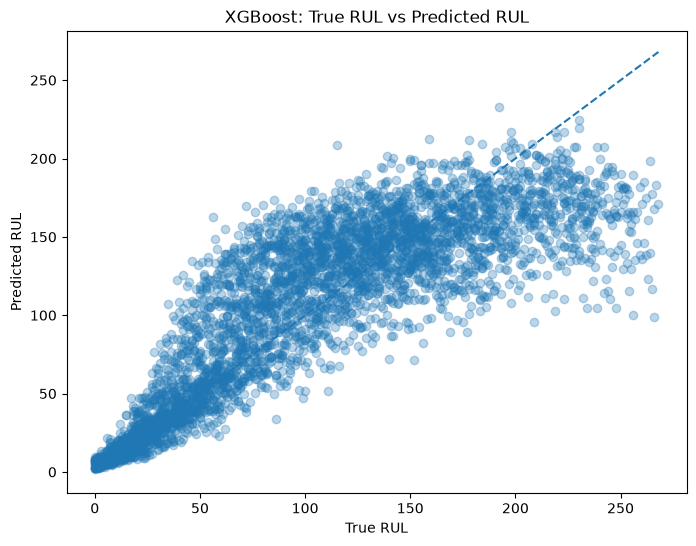

In [50]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_val,
    y_pred_xgb,
    alpha=0.3
)

min_rul = min(y_val.min(), y_pred_xgb.min())
max_rul = max(y_val.max(), y_pred_xgb.max())

plt.plot(
    [min_rul, max_rul],
    [min_rul, max_rul],
    linestyle="--"
)

plt.xlabel("True RUL")
plt.ylabel("Predicted RUL")
plt.title("XGBoost: True RUL vs Predicted RUL")

plt.show()

In [51]:
xgb_importance = pd.Series(
    xgb_model.feature_importances_,
    index=selected_sensors
).sort_values(ascending=False)

xgb_importance

sensor_11    0.329386
sensor_4     0.208157
sensor_12    0.095511
sensor_9     0.090758
sensor_7     0.046693
sensor_20    0.040851
sensor_15    0.037582
sensor_14    0.034251
sensor_17    0.029654
sensor_21    0.026475
sensor_13    0.016680
sensor_8     0.015667
sensor_3     0.014336
sensor_2     0.013999
dtype: float32

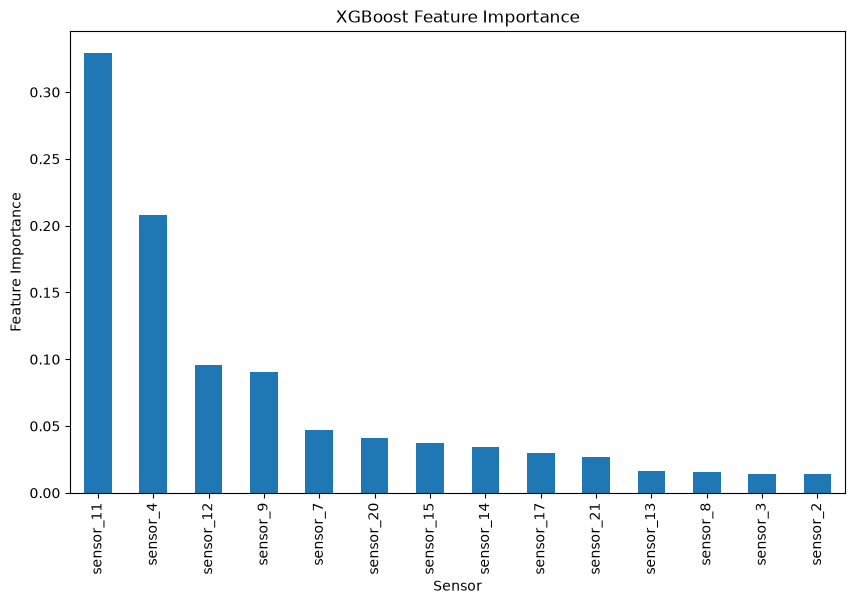

In [52]:
plt.figure(figsize=(10, 6))

xgb_importance.plot(kind="bar")

plt.xlabel("Sensor")
plt.ylabel("Feature Importance")
plt.title("XGBoost Feature Importance")

plt.show()

In [53]:
model_results

,Model,MAE,RMSE
0,Random Forest,25.879071,35.407605
1,XGBoost,25.714445,35.224112


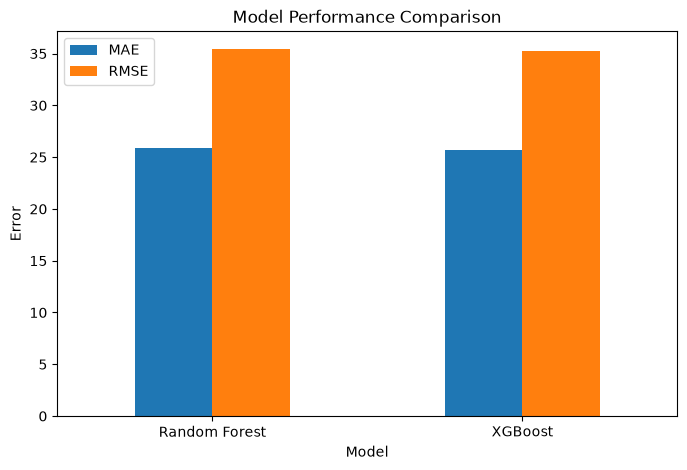

In [54]:
model_results.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.ylabel("Error")
plt.title("Model Performance Comparison")
plt.xticks(rotation=0)

plt.show()

In [55]:
model_results.to_csv(
    RESULTS_DIR / "validation_rf_xgb_comparison.csv",
    index=False
)

## 7. LSTM时序预测模型

与随机森林、XGBoost使用单个运行周期的传感器数据不同，LSTM利用连续运行周期的历史信息预测RUL。

首先基于训练集进行特征标准化，再按照发动机编号构建长度为30的滑动时间窗口。

每个样本包含连续30个运行周期、14个传感器的测量数据，预测窗口末端的RUL。

In [56]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

train_scaled = train_data.copy()
val_scaled = val_data.copy()

train_scaled[selected_sensors] = scaler.fit_transform(
    train_data[selected_sensors]
)

val_scaled[selected_sensors] = scaler.transform(
    val_data[selected_sensors]
)

print("标准化完成")

标准化完成


In [57]:
def create_sequences(df, feature_cols, seq_len=30):
    
    X_seq = []
    y_seq = []
    end_indices = []

    for unit in df["unit"].unique():

        unit_df = df[
            df["unit"] == unit
        ].sort_values("cycle")

        features = unit_df[feature_cols].values
        targets = unit_df["RUL"].values

        for i in range(seq_len - 1, len(unit_df)):

            X_seq.append(
                features[i-seq_len+1:i+1]
            )

            y_seq.append(
                targets[i]
            )

            end_indices.append(
                unit_df.index[i]
            )

    return (
        np.array(X_seq),
        np.array(y_seq),
        np.array(end_indices)
    )

In [58]:
X_train_seq, y_train_seq, train_end_idx = create_sequences(
    train_scaled,
    selected_sensors,
    seq_len=30
)

X_val_seq, y_val_seq, val_end_idx = create_sequences(
    val_scaled,
    selected_sensors,
    seq_len=30
)

print("LSTM训练输入形状：", X_train_seq.shape)
print("LSTM训练标签形状：", y_train_seq.shape)

print("LSTM验证输入形状：", X_val_seq.shape)
print("LSTM验证标签形状：", y_val_seq.shape)

LSTM训练输入形状： (14241, 30, 14)
LSTM训练标签形状： (14241,)
LSTM验证输入形状： (3490, 30, 14)
LSTM验证标签形状： (3490,)


In [59]:
import torch

print("PyTorch版本：", torch.__version__)
print("是否支持GPU：", torch.cuda.is_available())

PyTorch版本： 2.14.0+cpu
是否支持GPU： False


In [60]:
%pip install torch

Looking in indexes: https://mirrors.tuna.tsinghua.edu.cn/pypi/web/simple
Note: you may need to restart the kernel to use updated packages.


In [61]:
X_train_seq

array([[[-1.58119086, -1.09266247, -1.96301407, ..., -1.42624592,
          0.6786845 ,  1.5644361 ],
        [-1.72172228, -0.56515529, -1.75666396, ..., -0.77952854,
          1.34584413,  1.09889538],
        [-2.26377202, -0.35645308, -1.10638223, ..., -1.42624592,
          1.62382731,  1.25252381],
        ...,
        [-1.28005212, -1.46076717, -1.27480855, ..., -2.07296329,
          0.73428113,  1.38753063],
        [-1.19974845, -1.10252242, -1.20453797, ..., -2.07296329,
          0.8454744 ,  1.25159273],
        [-1.80202594, -0.02778817, -1.54027518, ..., -1.42624592,
          1.56823067,  1.00578723]],

       [[-1.72172228, -0.56515529, -1.75666396, ..., -0.77952854,
          1.34584413,  1.09889538],
        [-2.26377202, -0.35645308, -1.10638223, ..., -1.42624592,
          1.62382731,  1.25252381],
        [-2.00278511, -1.04171941, -1.42761917, ..., -1.42624592,
          1.73502058,  1.9759741 ],
        ...,
        [-1.19974845, -1.10252242, -1.20453797, ..., -

In [62]:
import torch
from torch.utils.data import TensorDataset, DataLoader

X_train_tensor = torch.tensor(
    X_train_seq,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train_seq,
    dtype=torch.float32
).unsqueeze(1)

X_val_tensor = torch.tensor(
    X_val_seq,
    dtype=torch.float32
)

y_val_tensor = torch.tensor(
    y_val_seq,
    dtype=torch.float32
).unsqueeze(1)

In [63]:
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

val_dataset = TensorDataset(
    X_val_tensor,
    y_val_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False
)

print("训练Batch数量：", len(train_loader))
print("验证Batch数量：", len(val_loader))

训练Batch数量： 223
验证Batch数量： 55


### 7.1 LSTM网络结构与训练

构建单层LSTM网络，输入维度为14，隐藏层维度为64。

通过全连接层将最后一个时间步的隐藏状态映射为RUL预测值。

采用均方误差（MSE）作为损失函数，使用Adam优化器训练30个Epoch，并记录训练与验证损失。

In [64]:
import torch
import torch.nn as nn

class RULLSTM(nn.Module):
    def __init__(self, input_size=14, hidden_size=64, num_layers=1):
        super(RULLSTM, self).__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        lstm_out, _ = self.lstm(x)

        last_output = lstm_out[:, -1, :]

        rul = self.fc(last_output)

        return rul

In [65]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

lstm_model = RULLSTM(
    input_size=len(selected_sensors),
    hidden_size=64,
    num_layers=1
).to(device)

print("当前设备：", device)
print(lstm_model)

当前设备： cpu
RULLSTM(
  (lstm): LSTM(14, 64, batch_first=True)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


In [66]:
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    lstm_model.parameters(),
    lr=0.001
)

In [67]:
num_epochs = 30

train_losses = []
val_losses = []

for epoch in range(num_epochs):

    # --------------------
    # 训练阶段
    # --------------------
    lstm_model.train()

    total_train_loss = 0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = lstm_model(X_batch)

        loss = criterion(
            predictions,
            y_batch
        )

        loss.backward()

        optimizer.step()

        total_train_loss += loss.item()

    avg_train_loss = (
        total_train_loss / len(train_loader)
    )

    # --------------------
    # 验证阶段
    # --------------------
    lstm_model.eval()

    total_val_loss = 0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = lstm_model(X_batch)

            loss = criterion(
                predictions,
                y_batch
            )

            total_val_loss += loss.item()

    avg_val_loss = (
        total_val_loss / len(val_loader)
    )

    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)

    print(
        f"Epoch {epoch+1:02d}/{num_epochs} | "
        f"Train Loss: {avg_train_loss:.2f} | "
        f"Val Loss: {avg_val_loss:.2f}"
    )

Epoch 01/30 | Train Loss: 10997.05 | Val Loss: 8540.54
Epoch 02/30 | Train Loss: 8634.45 | Val Loss: 6745.82
Epoch 03/30 | Train Loss: 6980.10 | Val Loss: 5384.44
Epoch 04/30 | Train Loss: 5699.00 | Val Loss: 4325.20
Epoch 05/30 | Train Loss: 4642.81 | Val Loss: 3431.53
Epoch 06/30 | Train Loss: 3796.81 | Val Loss: 2760.21
Epoch 07/30 | Train Loss: 3132.32 | Val Loss: 2209.27
Epoch 08/30 | Train Loss: 2641.52 | Val Loss: 1819.76
Epoch 09/30 | Train Loss: 2253.74 | Val Loss: 1546.77
Epoch 10/30 | Train Loss: 1953.86 | Val Loss: 1345.86
Epoch 11/30 | Train Loss: 1709.98 | Val Loss: 1120.45
Epoch 12/30 | Train Loss: 1534.72 | Val Loss: 982.23
Epoch 13/30 | Train Loss: 1392.59 | Val Loss: 914.42
Epoch 14/30 | Train Loss: 1266.37 | Val Loss: 786.42
Epoch 15/30 | Train Loss: 1186.04 | Val Loss: 726.02
Epoch 16/30 | Train Loss: 1102.83 | Val Loss: 713.75
Epoch 17/30 | Train Loss: 1039.02 | Val Loss: 720.49
Epoch 18/30 | Train Loss: 999.82 | Val Loss: 650.89
Epoch 19/30 | Train Loss: 937.15 | 

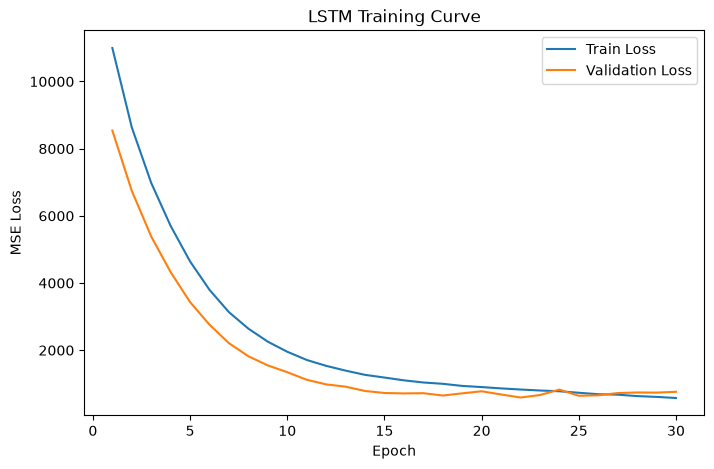

In [68]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, num_epochs + 1),
    train_losses,
    label="Train Loss"
)

plt.plot(
    range(1, num_epochs + 1),
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("LSTM Training Curve")
plt.legend()

plt.show()

In [69]:
lstm_model.eval()

predictions = []

with torch.no_grad():

    for X_batch, _ in val_loader:

        X_batch = X_batch.to(device)

        pred = lstm_model(X_batch)

        predictions.extend(
            pred.cpu().numpy().flatten()
        )

y_pred_lstm = np.array(predictions)

print("前10个真实RUL：")
print(y_val_seq[:10])

print("\n前10个LSTM预测RUL：")
print(np.round(y_pred_lstm[:10], 2))

前10个真实RUL：
[162 161 160 159 158 157 156 155 154 153]

前10个LSTM预测RUL：
[183.33 185.71 186.03 186.81 188.13 188.29 189.14 189.81 189.54 189.73]


In [70]:
lstm_mae = mean_absolute_error(
    y_val_seq,
    y_pred_lstm
)

lstm_rmse = np.sqrt(
    mean_squared_error(
        y_val_seq,
        y_pred_lstm
    )
)

print(
    "LSTM MAE：",
    round(lstm_mae, 2)
)

print(
    "LSTM RMSE：",
    round(lstm_rmse, 2)
)

LSTM MAE： 19.2
LSTM RMSE： 27.71


### 7.2 三种模型的公平验证集比较

由于LSTM采用长度为30的时间窗口，其有效验证样本与随机森林、XGBoost原始验证样本数量不同。

为保证评价口径一致，将三个模型的预测结果对齐至相同的窗口末端样本，再统一计算MAE和RMSE，比较不同模型的预测性能。

In [71]:
X_val_fair = val_data.loc[
    val_end_idx,
    selected_sensors
]

y_val_fair = val_data.loc[
    val_end_idx,
    "RUL"
].values

In [72]:
y_pred_rf_fair = rf_model.predict(
    X_val_fair
)

rf_mae_fair = mean_absolute_error(
    y_val_fair,
    y_pred_rf_fair
)

rf_rmse_fair = np.sqrt(
    mean_squared_error(
        y_val_fair,
        y_pred_rf_fair
    )
)

In [73]:
y_pred_xgb_fair = xgb_model.predict(
    X_val_fair
)

xgb_mae_fair = mean_absolute_error(
    y_val_fair,
    y_pred_xgb_fair
)

xgb_rmse_fair = np.sqrt(
    mean_squared_error(
        y_val_fair,
        y_pred_xgb_fair
    )
)

In [74]:
fair_model_results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "XGBoost",
        "LSTM"
    ],
    "MAE": [
        rf_mae_fair,
        xgb_mae_fair,
        lstm_mae
    ],
    "RMSE": [
        rf_rmse_fair,
        xgb_rmse_fair,
        lstm_rmse
    ]
})

fair_model_results

,Model,MAE,RMSE
0,Random Forest,23.476072,32.031207
1,XGBoost,23.259352,31.614462
2,LSTM,19.204477,27.708951


In [75]:
fair_model_results.to_csv(
    RESULTS_DIR / "validation_model_comparison.csv",
    index=False
)

print("验证集模型结果已保存")

验证集模型结果已保存


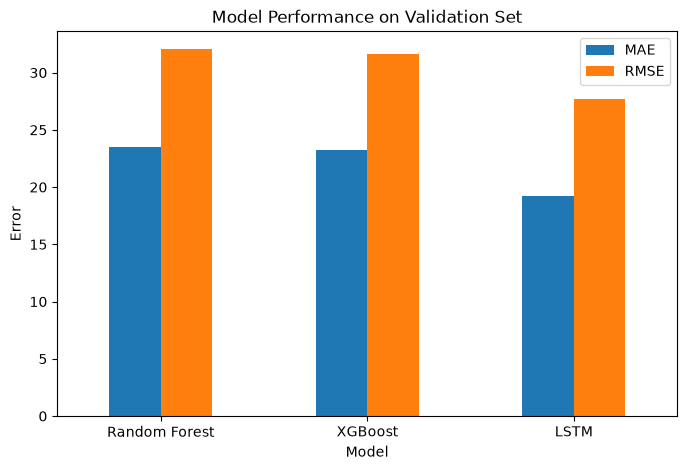

In [76]:
fair_model_results.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.ylabel("Error")
plt.title("Model Performance on Validation Set")
plt.xticks(rotation=0)
plt.show()

## 8. 正式测试集预测与模型评价

读取FD001官方测试数据及真实剩余寿命标签，对100台测试发动机进行RUL预测。

随机森林和XGBoost使用各发动机最后一个观测周期的传感器数据，LSTM使用对应的历史时间窗口。

统一计算MAE和RMSE，比较三种模型在独立测试集上的预测性能。

In [77]:
test_path = DATA_DIR / "test_FD001.txt"
rul_path = DATA_DIR / "RUL_FD001.txt"

test_df = pd.read_csv(
    test_path,
    sep=r"\s+",
    header=None
)

test_rul = pd.read_csv(
    rul_path,
    sep=r"\s+",
    header=None
)

In [78]:
print("测试集形状：", test_df.shape)
print("真实RUL数量：", test_rul.shape)

test_df.head()

测试集形状： (13096, 26)
真实RUL数量： (100, 1)


,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,521.72,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,522.16,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,521.97,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,521.38,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,522.15,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130


In [79]:
test_df.columns = column_names

test_df.head()

,unit,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,521.72,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,522.16,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,521.97,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,521.38,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,522.15,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130


In [80]:
test_last = (
    test_df
    .sort_values(["unit", "cycle"])
    .groupby("unit")
    .tail(1)
    .sort_values("unit")
)

print(test_last.shape)
test_last[["unit", "cycle"]].head()

(100, 26)


,unit,cycle
30,1,31
79,2,49
205,3,126
311,4,106
409,5,98


In [81]:
X_test_tree = test_last[selected_sensors]

In [82]:
rf_test_pred = rf_model.predict(X_test_tree)

xgb_test_pred = xgb_model.predict(X_test_tree)

In [83]:
y_test_true = test_rul.iloc[:, 0].values

In [84]:
rf_test_mae = mean_absolute_error(
    y_test_true,
    rf_test_pred
)

rf_test_rmse = np.sqrt(
    mean_squared_error(
        y_test_true,
        rf_test_pred
    )
)

xgb_test_mae = mean_absolute_error(
    y_test_true,
    xgb_test_pred
)

xgb_test_rmse = np.sqrt(
    mean_squared_error(
        y_test_true,
        xgb_test_pred
    )
)

print("RF Test MAE:", round(rf_test_mae, 2))
print("RF Test RMSE:", round(rf_test_rmse, 2))

print("XGB Test MAE:", round(xgb_test_mae, 2))
print("XGB Test RMSE:", round(xgb_test_rmse, 2))

RF Test MAE: 25.11
RF Test RMSE: 34.38
XGB Test MAE: 23.54
XGB Test RMSE: 32.94


In [85]:
test_scaled = test_df.copy()

test_scaled[selected_sensors] = scaler.transform(
    test_df[selected_sensors]
)

In [86]:
def create_test_sequences(
    df,
    feature_cols,
    seq_len=30
):
    X_seq = []
    units = []

    for unit in df["unit"].unique():

        unit_df = (
            df[df["unit"] == unit]
            .sort_values("cycle")
        )

        features = unit_df[
            feature_cols
        ].values

        if len(features) >= seq_len:

            seq = features[-seq_len:]

        else:

            # 如果序列不足30步，
            # 用最早状态进行前端填充
            pad_length = seq_len - len(features)

            padding = np.repeat(
                features[[0]],
                pad_length,
                axis=0
            )

            seq = np.vstack([
                padding,
                features
            ])

        X_seq.append(seq)
        units.append(unit)

    return (
        np.array(X_seq),
        np.array(units)
    )

In [87]:
X_test_seq, test_units = create_test_sequences(
    test_scaled,
    selected_sensors,
    seq_len=30
)

print("LSTM测试数据形状：", X_test_seq.shape)

LSTM测试数据形状： (100, 30, 14)


In [88]:
X_test_tensor = torch.tensor(
    X_test_seq,
    dtype=torch.float32
).to(device)

In [89]:
lstm_model.eval()

with torch.no_grad():

    lstm_test_pred = (
        lstm_model(X_test_tensor)
        .cpu()
        .numpy()
        .flatten()
    )

In [90]:
lstm_test_mae = mean_absolute_error(
    y_test_true,
    lstm_test_pred
)

lstm_test_rmse = np.sqrt(
    mean_squared_error(
        y_test_true,
        lstm_test_pred
    )
)

print(
    "LSTM Test MAE:",
    round(lstm_test_mae, 2)
)

print(
    "LSTM Test RMSE:",
    round(lstm_test_rmse, 2)
)

LSTM Test MAE: 18.39
LSTM Test RMSE: 27.61


In [91]:
test_model_results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "XGBoost",
        "LSTM"
    ],
    "MAE": [
        rf_test_mae,
        xgb_test_mae,
        lstm_test_mae
    ],
    "RMSE": [
        rf_test_rmse,
        xgb_test_rmse,
        lstm_test_rmse
    ]
})

test_model_results

,Model,MAE,RMSE
0,Random Forest,25.108100,34.376223
1,XGBoost,23.535965,32.940798
2,LSTM,18.394571,27.612798


In [92]:
test_model_results.to_csv(
    RESULTS_DIR / "test_model_results.csv",
    index=False
)

test_model_results

,Model,MAE,RMSE
0,Random Forest,25.108100,34.376223
1,XGBoost,23.535965,32.940798
2,LSTM,18.394571,27.612798


In [93]:
import joblib
import torch

# 保存随机森林
joblib.dump(
    rf_model,
    MODELS_DIR / "random_forest_model.pkl"
)

# 保存XGBoost
joblib.dump(
    xgb_model,
    MODELS_DIR / "xgboost_model.pkl"
)

# 保存LSTM
torch.save(
    lstm_model.state_dict(),
    MODELS_DIR / "lstm_model.pth"
)

print("三个模型保存完成")

三个模型保存完成


## 9. 基于残差分位数的RUL预测区间

为了分析模型预测结果的不确定性，采用XGBoost验证集的绝对预测残差构建预测区间。

提取绝对残差的90%分位数，作为预测区间半宽，并将预测区间下界限制为非负值。

随后计算官方测试集上的实际覆盖率和平均区间宽度，评价预测区间的表现。

需要注意，该方法属于基于验证残差的经验区间估计，不代表在所有数据分布下都能保证90%的覆盖率。

In [94]:
xgb_residuals = np.abs(
    y_val.values - y_pred_xgb
)

print("残差数量：", len(xgb_residuals))
print("平均绝对残差：", round(xgb_residuals.mean(), 2))

残差数量： 4070
平均绝对残差： 25.71


In [95]:
alpha = 0.10

q = np.quantile(
    xgb_residuals,
    1 - alpha
)

print(
    "90%预测区间半宽：",
    round(q, 2)
)

90%预测区间半宽： 60.31


In [96]:
lower_xgb = np.maximum(
    0,
    xgb_test_pred - q
)

upper_xgb = xgb_test_pred + q

In [97]:
uncertainty_results = pd.DataFrame({
    "True_RUL": y_test_true,
    "Predicted_RUL": xgb_test_pred,
    "Lower_90": lower_xgb,
    "Upper_90": upper_xgb
})

uncertainty_results.head(10)

,True_RUL,Predicted_RUL,Lower_90,Upper_90
0,112,174.228241,113.921079,234.535403
1,98,152.412125,92.104963,212.719286
2,69,63.955173,3.648012,124.262335
3,82,100.739487,40.432325,161.046648
4,91,127.170792,66.863630,187.477953
5,93,129.111572,68.804411,189.418734
6,91,119.753998,59.446836,180.061160
7,95,107.228592,46.921430,167.535754
8,111,116.760536,56.453374,177.067698
9,96,132.845474,72.538313,193.152636


In [98]:
covered = (
    (y_test_true >= lower_xgb)
    &
    (y_test_true <= upper_xgb)
)

coverage = covered.mean()

print(
    "实际覆盖率：",
    round(coverage * 100, 2),
    "%"
)

实际覆盖率： 91.0 %


In [99]:
interval_width = (
    upper_xgb - lower_xgb
)

mean_interval_width = (
    interval_width.mean()
)

print(
    "平均预测区间宽度：",
    round(mean_interval_width, 2)
)

平均预测区间宽度： 110.14


In [100]:
uncertainty_results.to_csv(
    RESULTS_DIR / "prediction_intervals_90.csv",
    index=False
)

## 10. 传感器故障注入与模型鲁棒性评估

为分析传感器异常对航空发动机RUL预测性能的影响，以XGBoost模型为研究对象，设计四类故障注入实验：

| 故障类型 | 实验方法 |
|---|---|
| Gaussian Noise | 根据传感器标准差添加随机噪声 |
| Bias | 添加固定幅度的传感器偏移 |
| Sensor Stuck | 将Sensor 11替换为固定值，模拟输出冻结 |
| Missing Data | 随机将部分传感器数据设置为缺失值 |

通过设置不同故障强度，计算各条件下的MAE和RMSE，并与正常数据进行对比，分析模型对不同传感器异常的敏感程度。

其中，当前Sensor Stuck实验是针对测试输入的简化故障模拟。

In [101]:
X_test_clean = X_test_tree.copy()

print("正常测试数据形状：", X_test_clean.shape)

正常测试数据形状： (100, 14)


In [102]:
sensor_train_std = train_data[selected_sensors].std()

sensor_train_std

sensor_2      0.498124
sensor_3      6.085409
sensor_4      8.965616
sensor_7      0.877772
sensor_8      0.070647
sensor_9     22.659801
sensor_11     0.265733
sensor_12     0.734990
sensor_13     0.071709
sensor_14    19.587082
sensor_15     0.037508
sensor_17     1.546317
sensor_20     0.179872
sensor_21     0.107405
dtype: float64

In [103]:
def inject_gaussian_noise(
    X,
    sensor_std,
    severity=0.5,
    random_state=42
):
    rng = np.random.default_rng(random_state)

    X_fault = X.copy()

    for sensor in X.columns:
        noise = rng.normal(
            loc=0,
            scale=sensor_std[sensor] * severity,
            size=len(X)
        )

        X_fault[sensor] = X_fault[sensor] + noise

    return X_fault

In [104]:
noise_levels = [
    0.0,
    0.25,
    0.5,
    1.0,
    2.0
]

noise_results = []

for severity in noise_levels:

    if severity == 0:
        X_fault = X_test_clean.copy()

    else:
        X_fault = inject_gaussian_noise(
            X_test_clean,
            sensor_train_std,
            severity=severity
        )

    pred = xgb_model.predict(X_fault)

    mae = mean_absolute_error(
        y_test_true,
        pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test_true,
            pred
        )
    )

    noise_results.append({
        "Severity": severity,
        "MAE": mae,
        "RMSE": rmse
    })

noise_results = pd.DataFrame(noise_results)

noise_results

,Severity,MAE,RMSE
0,0.00,23.535965,32.940798
1,0.25,25.967897,35.028077
2,0.50,27.277298,36.284677
3,1.00,33.350460,43.055333
4,2.00,48.882641,60.600942


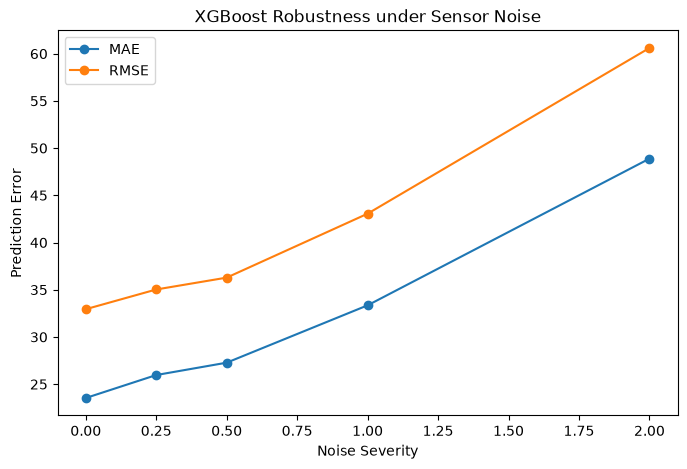

In [105]:
plt.figure(figsize=(8, 5))

plt.plot(
    noise_results["Severity"],
    noise_results["MAE"],
    marker="o",
    label="MAE"
)

plt.plot(
    noise_results["Severity"],
    noise_results["RMSE"],
    marker="o",
    label="RMSE"
)

plt.xlabel("Noise Severity")
plt.ylabel("Prediction Error")
plt.title("XGBoost Robustness under Sensor Noise")
plt.legend()

plt.show()

In [106]:
def inject_bias(
    X,
    sensor_std,
    severity=0.5
):
    X_fault = X.copy()

    for sensor in X.columns:

        bias = (
            sensor_std[sensor]
            * severity
        )

        X_fault[sensor] = (
            X_fault[sensor] + bias
        )

    return X_fault

In [107]:
bias_levels = [
    0.0,
    0.25,
    0.5,
    1.0,
    2.0
]

bias_results = []

for severity in bias_levels:

    if severity == 0:
        X_fault = X_test_clean.copy()

    else:
        X_fault = inject_bias(
            X_test_clean,
            sensor_train_std,
            severity=severity
        )

    pred = xgb_model.predict(X_fault)

    mae = mean_absolute_error(
        y_test_true,
        pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test_true,
            pred
        )
    )

    bias_results.append({
        "Severity": severity,
        "MAE": mae,
        "RMSE": rmse
    })

bias_results = pd.DataFrame(
    bias_results
)

bias_results

,Severity,MAE,RMSE
0,0.00,23.535965,32.940798
1,0.25,19.678514,27.748186
2,0.50,17.924688,24.496635
3,1.00,22.381197,28.834281
4,2.00,19.497822,24.190892


In [108]:
X_stuck = X_test_clean.copy()

stuck_value = train_data[
    "sensor_11"
].median()

X_stuck["sensor_11"] = stuck_value

In [109]:
stuck_pred = xgb_model.predict(
    X_stuck
)

stuck_mae = mean_absolute_error(
    y_test_true,
    stuck_pred
)

stuck_rmse = np.sqrt(
    mean_squared_error(
        y_test_true,
        stuck_pred
    )
)

print(
    "Sensor 11 Stuck MAE:",
    round(stuck_mae, 2)
)

print(
    "Sensor 11 Stuck RMSE:",
    round(stuck_rmse, 2)
)

Sensor 11 Stuck MAE: 28.53
Sensor 11 Stuck RMSE: 35.45


In [110]:
def inject_missing(
    X,
    missing_rate=0.1,
    random_state=42
):
    rng = np.random.default_rng(
        random_state
    )

    X_fault = X.copy()

    mask = rng.random(
        X_fault.shape
    ) < missing_rate

    X_fault = X_fault.mask(mask)

    return X_fault

In [111]:
missing_levels = [
    0.0,
    0.05,
    0.10,
    0.20,
    0.30
]

missing_results = []

for rate in missing_levels:

    if rate == 0:
        X_fault = X_test_clean.copy()

    else:
        X_fault = inject_missing(
            X_test_clean,
            missing_rate=rate
        )

    pred = xgb_model.predict(
        X_fault
    )

    mae = mean_absolute_error(
        y_test_true,
        pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test_true,
            pred
        )
    )

    missing_results.append({
        "Missing Rate": rate,
        "MAE": mae,
        "RMSE": rmse
    })

missing_results = pd.DataFrame(
    missing_results
)

missing_results

,Missing Rate,MAE,RMSE
0,0.00,23.535965,32.940798
1,0.05,24.764141,34.487113
2,0.10,26.683611,35.686431
3,0.20,30.274546,40.550888
4,0.30,31.512417,40.716570


In [112]:
robustness_summary = pd.DataFrame({
    "Condition": [
        "Clean",
        "Gaussian Noise (1.0)",
        "Bias (1.0)",
        "Sensor 11 Stuck",
        "Missing 20%"
    ],
    "MAE": [
        xgb_test_mae,
        noise_results.loc[
            noise_results["Severity"] == 1.0,
            "MAE"
        ].values[0],
        bias_results.loc[
            bias_results["Severity"] == 1.0,
            "MAE"
        ].values[0],
        stuck_mae,
        missing_results.loc[
            missing_results["Missing Rate"] == 0.20,
            "MAE"
        ].values[0]
    ],
    "RMSE": [
        xgb_test_rmse,
        noise_results.loc[
            noise_results["Severity"] == 1.0,
            "RMSE"
        ].values[0],
        bias_results.loc[
            bias_results["Severity"] == 1.0,
            "RMSE"
        ].values[0],
        stuck_rmse,
        missing_results.loc[
            missing_results["Missing Rate"] == 0.20,
            "RMSE"
        ].values[0]
    ]
})

robustness_summary

,Condition,MAE,RMSE
0,Clean,23.535965,32.940798
1,Gaussian Noise (1.0),33.350460,43.055333
2,Bias (1.0),22.381197,28.834281
3,Sensor 11 Stuck,28.525572,35.447684
4,Missing 20%,30.274546,40.550888


In [113]:
robustness_summary.to_csv(
    RESULTS_DIR / "robustness_summary.csv",
    index=False
)

robustness_summary

,Condition,MAE,RMSE
0,Clean,23.535965,32.940798
1,Gaussian Noise (1.0),33.350460,43.055333
2,Bias (1.0),22.381197,28.834281
3,Sensor 11 Stuck,28.525572,35.447684
4,Missing 20%,30.274546,40.550888


### 10.1 传感器缺失与卡死异常检测

前面的鲁棒性实验分析了传感器异常对RUL预测性能的影响，但尚未判断异常能否被系统自动识别。

本节进一步构建两类异常检测方法：

1. **数据缺失检测：** 识别传感器数据中的缺失位置。
2. **传感器卡死检测：** 根据时间序列中连续不变的测量值识别传感器卡死。

通过人工注入已知异常，计算检测精确率（Precision）、召回率（Recall）和F1分数，并分析卡死异常的检测延迟。

本阶段仅进行异常检测，不进行数据修复。

In [114]:
# ============================================
# Step 2-1：准备异常检测数据
# ============================================

# 使用完整测试时间序列，而不是仅使用最后一个周期
detection_clean_df = (
    test_df
    .sort_values(["unit", "cycle"])
    .reset_index(drop=True)
    .copy()
)

print("测试数据总行数：", len(detection_clean_df))
print("发动机数量：", detection_clean_df["unit"].nunique())
print("使用的传感器数量：", len(selected_sensors))

# 检查原始测试数据是否包含缺失值
original_missing_count = (
    detection_clean_df[selected_sensors]
    .isna()
    .sum()
    .sum()
)

print("原始数据缺失值数量：", original_missing_count)

测试数据总行数： 13096
发动机数量： 100
使用的传感器数量： 14
原始数据缺失值数量： 0


In [115]:
# ============================================
# Step 2-2：注入20%的传感器数据缺失
# ============================================

missing_fault_df = detection_clean_df.copy()

# 复用原Code 110中的inject_missing函数
missing_fault_df[selected_sensors] = inject_missing(
    detection_clean_df[selected_sensors],
    missing_rate=0.20,
    random_state=42
)

# 记录人工注入的缺失位置，作为真实标签
missing_true = (
    detection_clean_df[selected_sensors].notna()
    &
    missing_fault_df[selected_sensors].isna()
)

# 缺失检测：直接检查NaN
missing_alarm = (
    missing_fault_df[selected_sensors].isna()
)

print("人工注入缺失数量：", int(missing_true.sum().sum()))
print("检测到的缺失数量：", int(missing_alarm.sum().sum()))

人工注入缺失数量： 36668
检测到的缺失数量： 36668


In [116]:
# ============================================
# Step 2-3：缺失检测性能评价
# ============================================

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

def evaluate_detection(y_true, y_pred, condition):

    # 统一转换为一维数组
    y_true = np.asarray(y_true).ravel().astype(int)
    y_pred = np.asarray(y_pred).ravel().astype(int)

    precision = precision_score(
        y_true, y_pred, zero_division=0
    )

    recall = recall_score(
        y_true, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_true, y_pred, zero_division=0
    )

    return {
        "Condition": condition,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "True_Anomalies": int(y_true.sum()),
        "Detected_Anomalies": int(y_pred.sum())
    }


missing_metrics = evaluate_detection(
    missing_true,
    missing_alarm,
    "Missing 20%"
)

pd.DataFrame([missing_metrics])

,Condition,Precision,Recall,F1,True_Anomalies,Detected_Anomalies
0,Missing 20%,1.0,1.0,1.0,36668,36668


In [117]:
# ============================================
# Step 2-4：构建时间序列Sensor Stuck故障
# ============================================

STUCK_SENSOR = "sensor_11"
STUCK_FAULT_LENGTH = 20

stuck_fault_df = detection_clean_df.copy()

# 真实异常标签：False表示正常，True表示人工注入的卡死
stuck_true = pd.Series(
    False,
    index=detection_clean_df.index
)

injected_units = []

for unit, group in detection_clean_df.groupby("unit"):

    group = group.sort_values("cycle")

    # 确保有足够的历史数据
    if len(group) <= STUCK_FAULT_LENGTH:
        continue

    # 该发动机最后20个周期
    fault_indices = group.index[-STUCK_FAULT_LENGTH:]

    # 故障开始前一个周期
    previous_index = group.index[-STUCK_FAULT_LENGTH - 1]

    # 将故障期间的传感器值固定为故障前的值
    stuck_value = group.loc[
        previous_index,
        STUCK_SENSOR
    ]

    stuck_fault_df.loc[
        fault_indices,
        STUCK_SENSOR
    ] = stuck_value

    # 记录故障真实位置
    stuck_true.loc[fault_indices] = True

    injected_units.append(unit)

print("注入卡死故障的发动机数量：", len(injected_units))
print("人工注入的异常周期数量：", int(stuck_true.sum()))

注入卡死故障的发动机数量： 100
人工注入的异常周期数量： 2000


In [118]:
# ============================================
# Step 2-5：连续卡死检测算法
# ============================================

MIN_STUCK_RUN = 5


def detect_stuck_online(
    df,
    sensor="sensor_11",
    min_run=5
):

    # 按发动机与运行周期排序
    data = df.sort_values(
        ["unit", "cycle"]
    ).copy()

    values = data[sensor]

    # 当前值是否与同一台发动机的上一周期完全相等
    same_as_previous = (
        data["unit"].eq(data["unit"].shift())
        &
        values.notna()
        &
        values.shift().notna()
        &
        values.eq(values.shift())
    )

    # 连续相同数值划分为同一个区间
    run_group = (~same_as_previous).cumsum()

    # 每个连续区间已持续的周期数量
    run_length = (
        data.groupby(run_group)
        .cumcount()
        + 1
    )

    # 连续不变周期达到阈值，触发告警
    alarm = pd.Series(
        run_length.to_numpy() >= min_run,
        index=data.index
    )

    # 恢复原始数据顺序
    return alarm.reindex(df.index).fillna(False).astype(bool)


# 未注入故障时的检测结果
clean_stuck_alarm = detect_stuck_online(
    detection_clean_df,
    sensor=STUCK_SENSOR,
    min_run=MIN_STUCK_RUN
)

# 注入故障后的检测结果
stuck_alarm = detect_stuck_online(
    stuck_fault_df,
    sensor=STUCK_SENSOR,
    min_run=MIN_STUCK_RUN
)

print("正常数据告警数量：", int(clean_stuck_alarm.sum()))
print("故障数据告警数量：", int(stuck_alarm.sum()))

正常数据告警数量： 0
故障数据告警数量： 1702


In [119]:
# ============================================
# Step 2-6：Sensor Stuck检测性能评价
# ============================================

stuck_metrics = evaluate_detection(
    stuck_true,
    stuck_alarm,
    "Sensor 11 Stuck"
)

# 分别汇总两类异常检测结果
detection_summary = pd.DataFrame([
    missing_metrics,
    stuck_metrics
])

print("异常检测指标：")
display(detection_summary)

# 正常测试序列的基线告警率
baseline_alarm_rate = clean_stuck_alarm.mean()

print(
    "未注入故障数据的卡死告警率：",
    round(baseline_alarm_rate * 100, 4),
    "%"
)

# 逐台发动机计算卡死事件检测情况和检测延迟
event_records = []

for unit in injected_units:

    unit_indices = detection_clean_df.index[
        detection_clean_df["unit"] == unit
    ]

    # 真实故障周期
    true_indices = unit_indices[
        stuck_true.loc[unit_indices].to_numpy()
    ]

    # 仅统计故障发生后的告警
    alarm_indices = unit_indices[
        (
            stuck_true.loc[unit_indices]
            &
            stuck_alarm.loc[unit_indices]
        ).to_numpy()
    ]

    fault_start_cycle = detection_clean_df.loc[
        true_indices[0],
        "cycle"
    ]

    detected = len(alarm_indices) > 0

    if detected:
        first_alarm_cycle = detection_clean_df.loc[
            alarm_indices[0],
            "cycle"
        ]

        delay = first_alarm_cycle - fault_start_cycle

    else:
        delay = np.nan

    event_records.append({
        "Unit": unit,
        "Detected": detected,
        "Detection_Delay": delay
    })


stuck_event_results = pd.DataFrame(event_records)

print(
    "卡死事件检测率：",
    stuck_event_results["Detected"].mean()
)

print(
    "平均检测延迟（周期）：",
    stuck_event_results["Detection_Delay"].mean()
)

display(stuck_event_results.head())

异常检测指标：


,Condition,Precision,Recall,F1,True_Anomalies,Detected_Anomalies
0,Missing 20%,1.0,1.000,1.000000,36668,36668
1,Sensor 11 Stuck,1.0,0.851,0.919503,2000,1702


未注入故障数据的卡死告警率： 0.0 %
卡死事件检测率： 1.0
平均检测延迟（周期）： 2.98


,Unit,Detected,Detection_Delay
0,1,True,3
1,2,True,3
2,3,True,3
3,4,True,3
4,5,True,3


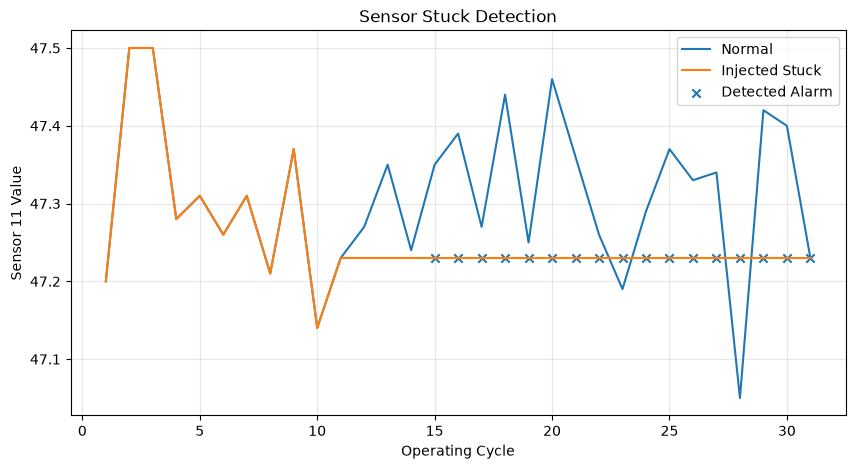

异常检测实验结果已保存至： D:\cmapss-rul-reliability\results


In [120]:
# ============================================
# Step 2-7：异常检测可视化与结果保存
# ============================================

# 保存两类异常检测指标
detection_summary.to_csv(
    RESULTS_DIR / "fault_detection_metrics.csv",
    index=False
)

# 保存每台发动机的卡死事件检测结果
stuck_event_results.to_csv(
    RESULTS_DIR / "stuck_detection_events.csv",
    index=False
)

# 保存逐周期卡死检测结果
stuck_detection_detail = pd.DataFrame({
    "Unit": detection_clean_df["unit"],
    "Cycle": detection_clean_df["cycle"],
    "Sensor_11_Original": detection_clean_df[STUCK_SENSOR],
    "Sensor_11_Fault": stuck_fault_df[STUCK_SENSOR],
    "True_Stuck": stuck_true,
    "Detected_Stuck": stuck_alarm
})

stuck_detection_detail.to_csv(
    RESULTS_DIR / "stuck_detection_detail.csv",
    index=False
)

# 选择一台发动机进行可视化
example_unit = injected_units[0]

example_normal = (
    detection_clean_df[
        detection_clean_df["unit"] == example_unit
    ].tail(35)
)

example_fault = stuck_fault_df.loc[
    example_normal.index
]

example_alarm = stuck_alarm.loc[
    example_normal.index
]

plt.figure(figsize=(10, 5))

plt.plot(
    example_normal["cycle"],
    example_normal[STUCK_SENSOR],
    label="Normal"
)

plt.plot(
    example_fault["cycle"],
    example_fault[STUCK_SENSOR],
    label="Injected Stuck"
)

plt.scatter(
    example_fault.loc[example_alarm, "cycle"],
    example_fault.loc[example_alarm, STUCK_SENSOR],
    marker="x",
    label="Detected Alarm"
)

plt.xlabel("Operating Cycle")
plt.ylabel("Sensor 11 Value")
plt.title("Sensor Stuck Detection")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig(
    RESULTS_DIR / "sensor_stuck_detection.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("异常检测实验结果已保存至：", RESULTS_DIR)

### 10.2 传感器异常数据修复

在前述异常检测实验的基础上，进一步研究传感器异常数据的修复方法。

针对不同故障类型，分别采用：

- **数据缺失：** 中位数填补和历史值填补；
- **传感器卡死：** 基于其他传感器信息的随机森林数值估计。

修复过程不使用官方测试集的真实RUL标签作为决策依据，以保证实验评价的独立性。

In [121]:
# ============================================
# Step 3-1：准备故障修复实验数据
# ============================================

# 官方测试集发动机顺序
test_units_order = test_last["unit"].to_numpy()

# 从完整时间序列提取每台发动机最后一个周期的数据
def get_last_features(df):
    last_df = (
        df.sort_values(["unit", "cycle"])
        .groupby("unit")
        .tail(1)
        .set_index("unit")
    )

    return last_df.loc[
        test_units_order,
        selected_sensors
    ].copy()


# 第三步使用的正常测试输入
X_clean_step3 = get_last_features(detection_clean_df)

# 检查是否与之前XGBoost测试数据完全一致
assert np.allclose(
    X_clean_step3.to_numpy(),
    X_test_clean.to_numpy(),
    equal_nan=True
), "第三步正常测试数据与之前的测试数据不一致"

assert len(X_clean_step3) == len(y_test_true)

# 检查第二步的Missing检测结果
assert (
    missing_fault_df[selected_sensors].isna()
    == missing_alarm
).all().all()

print("正常测试数据形状：", X_clean_step3.shape)
print("测试标签数量：", len(y_test_true))
print("数据一致性检查通过")

正常测试数据形状： (100, 14)
测试标签数量： 100
数据一致性检查通过


#### 10.2.1 数据缺失修复——中位数填补

使用训练集中各传感器的中位数替换缺失值。

该方法实现简单，不依赖历史运行状态，可作为数据修复的基线方法。但由于没有考虑发动机个体状态和退化趋势，填补结果可能与真实测量值存在偏差。

In [122]:
# ============================================
# Step 3-2：Missing修复——中位数填补
# ============================================

# 使用训练集计算每个传感器的中位数
sensor_medians = train_data[selected_sensors].median()

# 复制故障数据，不修改原始数据
missing_median_df = missing_fault_df.copy()

# 对检测出的缺失位置进行填补
missing_median_df[selected_sensors] = (
    missing_median_df[selected_sensors]
    .fillna(sensor_medians)
)

print(
    "修复前缺失数量：",
    missing_fault_df[selected_sensors].isna().sum().sum()
)

print(
    "修复后缺失数量：",
    missing_median_df[selected_sensors].isna().sum().sum()
)

assert not missing_median_df[selected_sensors].isna().any().any()

修复前缺失数量： 36668
修复后缺失数量： 0


#### 10.2.2 数据缺失修复——历史值填补

根据同一台发动机的历史传感器数据，使用最近一次有效测量值填补当前缺失值。

该方法能够保留发动机近期运行状态，并且只利用当前时刻之前的数据。当历史数据不足时，使用训练集传感器中位数作为备用填充值。

In [123]:
# ============================================
# Step 3-3：Missing修复——历史值填补
# ============================================

missing_history_df = missing_fault_df.copy()

# 同一台发动机内部，利用历史有效值向前填补
historical_filled = (
    missing_history_df
    .groupby("unit")[selected_sensors]
    .ffill()
)

# 若发动机最初几个周期就缺失，
# 则使用训练集中的中位数作为备用值
missing_history_df[selected_sensors] = (
    historical_filled.fillna(sensor_medians)
)

print(
    "修复前缺失数量：",
    missing_fault_df[selected_sensors].isna().sum().sum()
)

print(
    "历史值修复后缺失数量：",
    missing_history_df[selected_sensors].isna().sum().sum()
)

assert not missing_history_df[selected_sensors].isna().any().any()

修复前缺失数量： 36668
历史值修复后缺失数量： 0


#### 10.2.3 传感器卡死修复模型构建

针对Sensor 11卡死故障，利用其他13个传感器的测量信息估计Sensor 11的正常值。

采用随机森林回归模型，以其他传感器为输入、Sensor 11测量值为预测目标，并使用独立验证集评价传感器数值估计误差。

该模型仅用于传感器数据修复，不替代原有的RUL预测模型。

In [124]:
# ============================================
# Step 3-4：训练Sensor 11数值估计模型
# ============================================

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

STUCK_SENSOR = "sensor_11"

# 其他13个传感器作为输入
sensor11_features = [
    s for s in selected_sensors
    if s != STUCK_SENSOR
]

# 新建一个模型，专门预测Sensor 11测量值
sensor11_repair_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

# 只能使用训练集训练
sensor11_repair_model.fit(
    train_data[sensor11_features],
    train_data[STUCK_SENSOR]
)

# 利用验证集评价该模型对Sensor 11的估计误差
sensor11_val_pred = sensor11_repair_model.predict(
    val_data[sensor11_features]
)

sensor11_val_mae = mean_absolute_error(
    val_data[STUCK_SENSOR],
    sensor11_val_pred
)

print("Sensor 11数值估计模型训练完成")
print("输入传感器数量：", len(sensor11_features))
print("Sensor 11验证集MAE：", round(sensor11_val_mae, 4))

Sensor 11数值估计模型训练完成
输入传感器数量： 13
Sensor 11验证集MAE： 0.0885


#### 10.2.4 传感器卡死异常修复

根据上一阶段的Sensor Stuck检测结果，定位被判定为卡死的传感器测量值。

利用已训练的随机森林模型估计对应位置的正常数值，并替换异常读数。未触发告警的位置保持不变。

通过比较修复前后Sensor 11与原始正常测量值的误差，评价数据修复效果。

In [125]:
# ============================================
# Step 3-5：根据检测结果修复Sensor 11
# ============================================

# 复制人工注入卡死后的完整测试序列
stuck_repaired_df = stuck_fault_df.copy()

# 根据第二步的检测结果选择修复位置
repair_mask = (
    stuck_alarm
    .reindex(stuck_repaired_df.index)
    .fillna(False)
    .astype(bool)
)

# 利用其他13个传感器估计Sensor 11正常测量值
repaired_sensor11 = sensor11_repair_model.predict(
    stuck_repaired_df.loc[
        repair_mask,
        sensor11_features
    ]
)

# 只替换触发异常告警的位置
stuck_repaired_df.loc[
    repair_mask,
    STUCK_SENSOR
] = repaired_sensor11

print("检测并修复的周期数量：", int(repair_mask.sum()))

# 以下真实标签仅用于实验评价，不参与修复决策
sensor11_fault_mae = mean_absolute_error(
    detection_clean_df.loc[stuck_true, STUCK_SENSOR],
    stuck_fault_df.loc[stuck_true, STUCK_SENSOR]
)

sensor11_repaired_mae = mean_absolute_error(
    detection_clean_df.loc[stuck_true, STUCK_SENSOR],
    stuck_repaired_df.loc[stuck_true, STUCK_SENSOR]
)

print(
    "故障状态Sensor 11测量误差：",
    round(sensor11_fault_mae, 4)
)

print(
    "修复状态Sensor 11测量误差：",
    round(sensor11_repaired_mae, 4)
)

检测并修复的周期数量： 1702
故障状态Sensor 11测量误差： 0.132
修复状态Sensor 11测量误差： 0.0912


### 10.3 RUL预测性能恢复评价

为评价异常数据修复对下游预测任务的实际作用，使用原有XGBoost模型，分别对正常数据、故障数据及修复后数据进行RUL预测。

采用MAE和RMSE作为性能指标，比较不同状态下的预测误差变化，判断异常修复是否能够有效恢复模型预测性能。

实验中保持XGBoost模型及官方测试集真实标签不变，仅改变输入传感器数据。

In [126]:
# ============================================
# Step 3-6：RUL预测性能恢复实验
# ============================================

from sklearn.metrics import mean_absolute_error, mean_squared_error

# 所有实验使用相同的发动机和RUL真实标签
repair_experiments = {
    "Clean": detection_clean_df,

    "Missing_Fault_20%": missing_fault_df,
    "Missing_Median": missing_median_df,
    "Missing_History": missing_history_df,

    "Stuck_Fault_20Cycles": stuck_fault_df,
    "Stuck_Repaired_RF": stuck_repaired_df
}

repair_results = []

for condition, full_df in repair_experiments.items():

    # 提取每台发动机最后一个周期
    X_eval = get_last_features(full_df)

    # 使用原来的XGBoost预测RUL
    pred = xgb_model.predict(X_eval)

    mae = mean_absolute_error(
        y_test_true,
        pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test_true,
            pred
        )
    )

    repair_results.append({
        "Condition": condition,
        "MAE": mae,
        "RMSE": rmse
    })

repair_results = pd.DataFrame(repair_results)

print("故障修复前后RUL预测性能比较：")
display(repair_results.round(3))

故障修复前后RUL预测性能比较：


,Condition,MAE,RMSE
0,Clean,23.536,32.941
1,Missing_Fault_20%,27.475,35.709
2,Missing_Median,29.459,36.822
3,Missing_History,23.672,32.749
4,Stuck_Fault_20Cycles,27.511,36.457
5,Stuck_Repaired_RF,24.176,33.399


#### 10.3.1 性能恢复率计算与实验结果分析

采用性能恢复率衡量异常修复对RUL预测误差的改善程度。

在本次实验中：

- **中位数填补：** MAE由27.475增加至29.459，恢复率为-50.36%，修复后性能进一步下降。
- **历史值填补：** MAE由27.475降低至23.672，恢复率为96.56%，基本接近正常预测水平。
- **随机森林修复Sensor 11：** MAE由27.511降低至24.176，恢复率为83.89%，能够显著减轻卡死故障的影响。

实验表明，不同异常修复方法对RUL预测性能的影响存在明显差异。利用历史信息和多传感器关联信息，在当前实验条件下比简单中位数填补更加有效。

通过绘制MAE、RMSE对比图，并保存实验结果，为后续方法比较提供依据。

预测性能恢复率：


,Fault,Repair_Method,MAE_Clean,MAE_Fault,MAE_Repaired,MAE_Improvement,MAE_Recovery_Rate(%),RMSE_Clean,RMSE_Fault,RMSE_Repaired,RMSE_Improvement,RMSE_Recovery_Rate(%)
0,Missing_Fault_20%,Missing_Median,23.536,27.475,29.459,-1.984,-50.361,32.941,35.709,36.822,-1.113,-40.220
1,Missing_Fault_20%,Missing_History,23.536,27.475,23.672,3.803,96.557,32.941,35.709,32.749,2.960,106.938
2,Stuck_Fault_20Cycles,Stuck_Repaired_RF,23.536,27.511,24.176,3.335,83.891,32.941,36.457,33.399,3.058,86.965


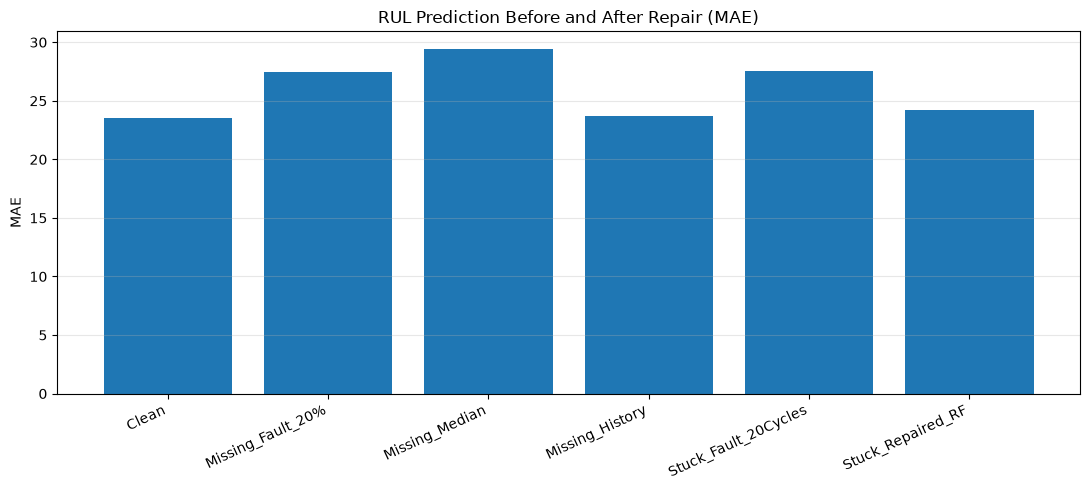

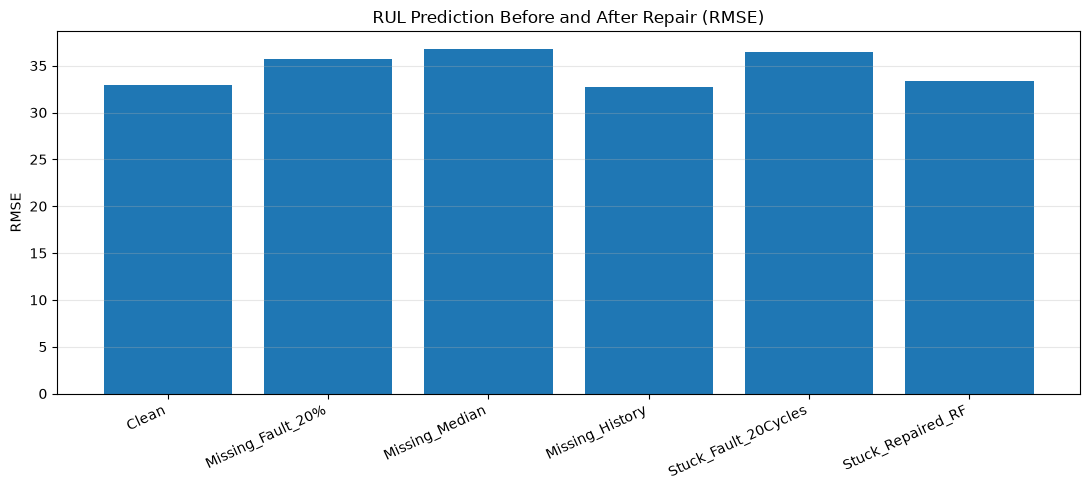

第三步实验结果已保存至： D:\cmapss-rul-reliability\results


In [127]:
# ============================================
# Step 3-7：性能恢复率计算与结果保存
# ============================================

import matplotlib.pyplot as plt
import joblib

result_table = repair_results.set_index("Condition")

clean_result = result_table.loc["Clean"]

repair_pairs = [
    ("Missing_Fault_20%", "Missing_Median"),
    ("Missing_Fault_20%", "Missing_History"),
    ("Stuck_Fault_20Cycles", "Stuck_Repaired_RF")
]

recovery_records = []

for fault_name, repaired_name in repair_pairs:

    fault = result_table.loc[fault_name]
    repaired = result_table.loc[repaired_name]

    record = {
        "Fault": fault_name,
        "Repair_Method": repaired_name
    }

    for metric in ["MAE", "RMSE"]:

        clean_error = clean_result[metric]
        fault_error = fault[metric]
        repaired_error = repaired[metric]

        # 修复后相比故障状态降低了多少误差
        improvement = fault_error - repaired_error

        # 只在故障确实造成性能下降时计算恢复率
        if fault_error > clean_error:
            recovery_rate = (
                improvement / (fault_error - clean_error)
            ) * 100
        else:
            recovery_rate = np.nan

        record[f"{metric}_Clean"] = clean_error
        record[f"{metric}_Fault"] = fault_error
        record[f"{metric}_Repaired"] = repaired_error
        record[f"{metric}_Improvement"] = improvement
        record[f"{metric}_Recovery_Rate(%)"] = recovery_rate

    recovery_records.append(record)

recovery_summary = pd.DataFrame(recovery_records)

print("预测性能恢复率：")
display(recovery_summary.round(3))

# 保存实验评价数据
repair_results.to_csv(
    RESULTS_DIR / "repair_performance_comparison.csv",
    index=False
)

recovery_summary.to_csv(
    RESULTS_DIR / "repair_recovery_summary.csv",
    index=False
)

# 保存传感器修复模型
joblib.dump(
    sensor11_repair_model,
    MODELS_DIR / "sensor11_repair_model.pkl"
)

# 绘制MAE和RMSE对比图
for metric in ["MAE", "RMSE"]:

    plt.figure(figsize=(11, 5))

    plt.bar(
        repair_results["Condition"],
        repair_results[metric]
    )

    plt.ylabel(metric)
    plt.title(f"RUL Prediction Before and After Repair ({metric})")
    plt.xticks(rotation=25, ha="right")
    plt.grid(axis="y", alpha=0.3)

    plt.tight_layout()

    plt.savefig(
        RESULTS_DIR / f"repair_{metric.lower()}_comparison.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

print("第三步实验结果已保存至：", RESULTS_DIR)

### 10.4 多随机种子下的数据缺失修复实验

为验证异常修复结果是否受随机缺失位置影响，设置42、43、44、45、46共5个随机种子，重复开展20%数据缺失注入实验。

每组实验均使用相同的XGBoost模型，对比以下四种状态：

1. Clean：正常数据；
2. Fault：20%数据缺失；
3. Median：中位数填补；
4. History：历史值填补。

通过重复实验评价不同修复方法的稳定性，减少单次随机故障注入对实验结论的影响。

In [128]:
# ============================================
# Step 4-1：5组随机种子的Missing修复重复实验
# ============================================

from sklearn.metrics import mean_absolute_error, mean_squared_error

SEEDS = [42, 43, 44, 45, 46]
MISSING_RATE = 0.20

# 中位数只从训练数据计算
repeat_sensor_medians = train_data[selected_sensors].median()

# 记录5组实验结果
multiseed_records = []

# 正常测试集基线
X_repeat_clean = get_last_features(detection_clean_df)

clean_pred = xgb_model.predict(X_repeat_clean)

clean_mae_repeat = mean_absolute_error(
    y_test_true, clean_pred
)

clean_rmse_repeat = np.sqrt(
    mean_squared_error(y_test_true, clean_pred)
)

for seed in SEEDS:

    print(f"正在运行随机种子：{seed}")

    # 1. 重新注入20%数据缺失
    fault_df = detection_clean_df.copy()

    fault_df[selected_sensors] = inject_missing(
        detection_clean_df[selected_sensors],
        missing_rate=MISSING_RATE,
        random_state=seed
    )

    # 2. 中位数填补
    median_df = fault_df.copy()

    median_df[selected_sensors] = (
        median_df[selected_sensors]
        .fillna(repeat_sensor_medians)
    )

    # 3. 历史值填补
    history_df = fault_df.copy()

    history_values = (
        history_df
        .groupby("unit")[selected_sensors]
        .ffill()
    )

    history_df[selected_sensors] = (
        history_values.fillna(repeat_sensor_medians)
    )

    # 4. 构建对比组
    experiments = {
        "Clean": detection_clean_df,
        "Fault": fault_df,
        "Median": median_df,
        "History": history_df
    }

    injected_count = int(
        fault_df[selected_sensors].isna().sum().sum()
    )

    # 5. 使用同一个XGBoost模型进行RUL预测
    for method, current_df in experiments.items():

        X_eval = get_last_features(current_df)

        predictions = xgb_model.predict(X_eval)

        mae = mean_absolute_error(
            y_test_true, predictions
        )

        rmse = np.sqrt(
            mean_squared_error(
                y_test_true, predictions
            )
        )

        multiseed_records.append({
            "Seed": seed,
            "Method": method,
            "MAE": mae,
            "RMSE": rmse,
            "Injected_Missing": injected_count
        })

# 转换为DataFrame
multiseed_results = pd.DataFrame(multiseed_records)

print("\n5组实验完成")
print("实验记录数量：", len(multiseed_results))

display(multiseed_results.round(3))

正在运行随机种子：42
正在运行随机种子：43
正在运行随机种子：44
正在运行随机种子：45
正在运行随机种子：46

5组实验完成
实验记录数量： 20


,Seed,Method,MAE,RMSE,Injected_Missing
0,42,Clean,23.536,32.941,36668
1,42,Fault,27.475,35.709,36668
2,42,Median,29.459,36.822,36668
3,42,History,23.672,32.749,36668
4,43,Clean,23.536,32.941,36782
5,43,Fault,27.288,34.919,36782
6,43,Median,28.465,36.538,36782
7,43,History,23.536,33.014,36782
8,44,Clean,23.536,32.941,36745
9,44,Fault,27.600,35.085,36745


### 10.5 多随机种子实验结果分析

通过5组随机种子实验，统计不同修复方法的MAE、RMSE均值及标准差，并计算预测性能恢复率。

#### （1）预测误差对比

五组实验的平均结果如下：

| 实验状态 | MAE均值 | MAE标准差 | RMSE均值 |
|---|---:|---:|---:|
| Clean | 23.536 | 0.000 | 32.941 |
| Fault | 28.051 | 0.878 | 36.078 |
| Median | 28.077 | 1.096 | 35.361 |
| History | 23.888 | 0.722 | 33.127 |

#### （2）修复效果分析

- **中位数填补：** 平均MAE为28.077，与故障状态的28.051基本相当，平均性能恢复率为-3.90%，整体未能有效恢复预测精度。
- **历史值填补：** 平均MAE为23.888，接近正常状态的23.536，五组实验的平均性能恢复率为92.09%。
- **结果稳定性：** 历史值填补在全部5组实验中均降低了MAE，而中位数填补仅在3组实验中降低MAE。

#### （3）实验结论

历史值填补能够较稳定地缓解随机数据缺失引起的RUL预测性能下降。

相比之下，中位数填补效果受缺失位置影响更明显，部分实验中甚至导致预测误差增加。

但当前仅开展5组重复实验，结论仍限于FD001数据集及20%随机缺失条件。

In [129]:
# ============================================
# Step 4-2：汇总重复实验结果
# ============================================

# 计算各方法MAE和RMSE的均值、标准差
multiseed_summary = (
    multiseed_results
    .groupby("Method", as_index=False)
    .agg(
        MAE_Mean=("MAE", "mean"),
        MAE_Std=("MAE", "std"),
        RMSE_Mean=("RMSE", "mean"),
        RMSE_Std=("RMSE", "std")
    )
)

print("各方法的平均性能及标准差：")
display(multiseed_summary.round(3))


# 将每个随机种子的MAE整理成同一行
mae_pivot = multiseed_results.pivot(
    index="Seed",
    columns="Method",
    values="MAE"
)

# 故障相对正常状态增加的MAE
performance_loss = (
    mae_pivot["Fault"] - mae_pivot["Clean"]
)

# 当故障并未造成性能损失时，不计算恢复率
valid_loss = performance_loss.where(
    performance_loss > 0
)

# 逐种子性能恢复率
multiseed_recovery = pd.DataFrame({
    "Seed": mae_pivot.index,
    "Fault_MAE": mae_pivot["Fault"].values,
    "Median_MAE": mae_pivot["Median"].values,
    "History_MAE": mae_pivot["History"].values,

    "Median_Recovery_Rate(%)": (
        (mae_pivot["Fault"] - mae_pivot["Median"])
        / valid_loss * 100
    ).values,

    "History_Recovery_Rate(%)": (
        (mae_pivot["Fault"] - mae_pivot["History"])
        / valid_loss * 100
    ).values
})

print("各随机种子的MAE性能恢复率：")
display(multiseed_recovery.round(3))

print("平均恢复率：")
print(
    multiseed_recovery[
        ["Median_Recovery_Rate(%)",
         "History_Recovery_Rate(%)"]
    ].mean().round(2)
)

各方法的平均性能及标准差：


,Method,MAE_Mean,MAE_Std,RMSE_Mean,RMSE_Std
0,Clean,23.536,0.000,32.941,0.000
1,Fault,28.051,0.878,36.078,1.458
2,History,23.888,0.722,33.127,0.838
3,Median,28.077,1.096,35.361,1.489


各随机种子的MAE性能恢复率：


,Seed,Fault_MAE,Median_MAE,History_MAE,Median_Recovery_Rate(%),History_Recovery_Rate(%)
0,42,27.475,29.459,23.672,-50.361,96.557
1,43,27.288,28.465,23.536,-31.373,99.998
2,44,27.600,26.731,24.046,21.389,87.450
3,45,29.373,28.513,23.144,14.747,106.717
4,46,28.515,27.217,25.044,26.079,69.707


平均恢复率：
Median_Recovery_Rate(%)     -3.90
History_Recovery_Rate(%)    92.09
dtype: float64


#### 10.5.1 重复实验结果可视化

为了直观比较不同修复方法的预测性能，绘制五组随机种子下的平均MAE和RMSE柱状图。

使用误差棒表示不同随机种子之间的标准差，展示修复方法对随机故障位置变化的敏感程度。

同时保存各组实验结果、统计汇总表及性能恢复率数据，以支持后续实验分析与结果复现。

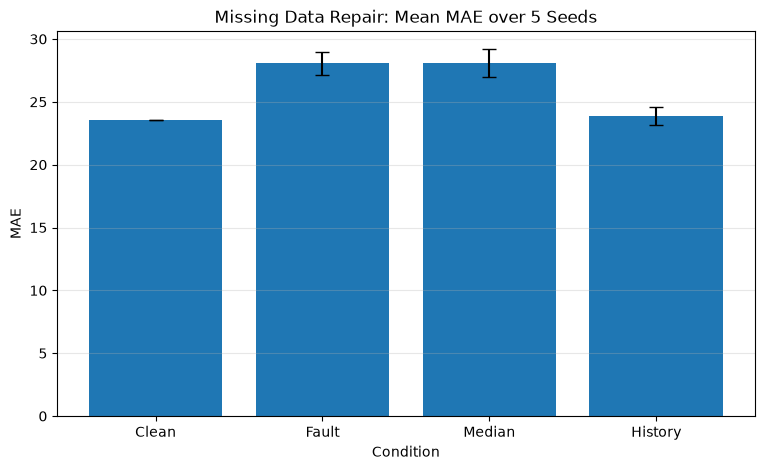

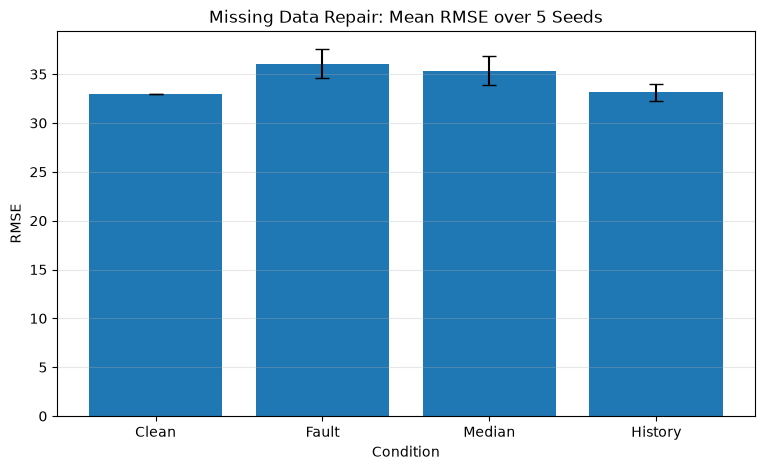

重复实验结果已保存至： D:\cmapss-rul-reliability\results


In [130]:
# ============================================
# Step 4-3：重复实验结果可视化与保存
# ============================================

import matplotlib.pyplot as plt

# 保存三份结果表
multiseed_results.to_csv(
    RESULTS_DIR / "missing_multiseed_results.csv",
    index=False
)

multiseed_summary.to_csv(
    RESULTS_DIR / "missing_multiseed_summary.csv",
    index=False
)

multiseed_recovery.to_csv(
    RESULTS_DIR / "missing_multiseed_recovery.csv",
    index=False
)


# 绘制MAE均值及标准差
method_order = ["Clean", "Fault", "Median", "History"]

plot_data = (
    multiseed_summary
    .set_index("Method")
    .loc[method_order]
)

plt.figure(figsize=(9, 5))

plt.bar(
    method_order,
    plot_data["MAE_Mean"],
    yerr=plot_data["MAE_Std"].fillna(0),
    capsize=5
)

plt.ylabel("MAE")
plt.xlabel("Condition")
plt.title("Missing Data Repair: Mean MAE over 5 Seeds")
plt.grid(axis="y", alpha=0.3)

plt.savefig(
    RESULTS_DIR / "missing_multiseed_mae.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 绘制RMSE均值及标准差
plt.figure(figsize=(9, 5))

plt.bar(
    method_order,
    plot_data["RMSE_Mean"],
    yerr=plot_data["RMSE_Std"].fillna(0),
    capsize=5
)

plt.ylabel("RMSE")
plt.xlabel("Condition")
plt.title("Missing Data Repair: Mean RMSE over 5 Seeds")
plt.grid(axis="y", alpha=0.3)

plt.savefig(
    RESULTS_DIR / "missing_multiseed_rmse.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("重复实验结果已保存至：", RESULTS_DIR)

## 11. XGBoost集成不确定性分析

构建由10个不同随机种子训练的XGBoost模型组成的预测集成。

对于同一个测试样本，计算各模型预测值的均值及标准差，以模型间预测分歧作为不确定性的近似指标。

进一步分析预测标准差与绝对预测误差之间的关系，并比较正常状态及不同传感器故障条件下的不确定性变化。

该指标反映模型集成的预测分歧，不等同于经过严格校准的预测置信度。

In [131]:
ensemble_models = []

for seed in range(10):

    model = XGBRegressor(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=seed,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    ensemble_models.append(model)

print("Ensemble模型数量：", len(ensemble_models))

Ensemble模型数量： 10


In [132]:
ensemble_test_predictions = []

for model in ensemble_models:

    pred = model.predict(X_test_clean)

    ensemble_test_predictions.append(pred)

ensemble_test_predictions = np.array(
    ensemble_test_predictions
)

print(
    "预测矩阵形状：",
    ensemble_test_predictions.shape
)

预测矩阵形状： (10, 100)


In [133]:
ensemble_mean = ensemble_test_predictions.mean(axis=0)

ensemble_std = ensemble_test_predictions.std(axis=0)

print("前5台发动机平均预测：")
print(np.round(ensemble_mean[:5], 2))

print("\n前5台发动机预测标准差：")
print(np.round(ensemble_std[:5], 2))

前5台发动机平均预测：
[172.34 145.76  66.84  98.3  128.4 ]

前5台发动机预测标准差：
[3.09 3.35 3.64 2.82 3.82]


In [134]:
ensemble_abs_error = np.abs(
    y_test_true - ensemble_mean
)

In [135]:
uncertainty_error_df = pd.DataFrame({
    "True_RUL": y_test_true,
    "Predicted_RUL": ensemble_mean,
    "Absolute_Error": ensemble_abs_error,
    "Uncertainty": ensemble_std
})

uncertainty_error_df.head()

,True_RUL,Predicted_RUL,Absolute_Error,Uncertainty
0,112,172.338760,60.338760,3.091851
1,98,145.763809,47.763809,3.354252
2,69,66.843674,2.156326,3.643929
3,82,98.297142,16.297142,2.822909
4,91,128.400070,37.400070,3.815576


In [136]:
error_uncertainty_corr = np.corrcoef(
    ensemble_abs_error,
    ensemble_std
)[0, 1]

print(
    "预测误差与不确定性的相关系数：",
    round(error_uncertainty_corr, 3)
)

预测误差与不确定性的相关系数： 0.445


In [137]:
fault_datasets = {
    "Clean": X_test_clean,

    "Gaussian Noise (1.0)": inject_gaussian_noise(
        X_test_clean,
        sensor_train_std,
        severity=1.0
    ),

    "Bias (1.0)": inject_bias(
        X_test_clean,
        sensor_train_std,
        severity=1.0
    ),

    "Sensor 11 Stuck": X_stuck,

    "Missing 20%": inject_missing(
        X_test_clean,
        missing_rate=0.20
    )
}

In [138]:
ensemble_fault_results = []

for condition, X_fault in fault_datasets.items():

    preds = []

    for model in ensemble_models:

        pred = model.predict(X_fault)

        preds.append(pred)

    preds = np.array(preds)

    mean_pred = preds.mean(axis=0)

    uncertainty = preds.std(axis=0)

    mae = mean_absolute_error(
        y_test_true,
        mean_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test_true,
            mean_pred
        )
    )

    mean_uncertainty = uncertainty.mean()

    ensemble_fault_results.append({
        "Condition": condition,
        "MAE": mae,
        "RMSE": rmse,
        "Mean_Uncertainty": mean_uncertainty
    })

ensemble_fault_results = pd.DataFrame(
    ensemble_fault_results
)

ensemble_fault_results

,Condition,MAE,RMSE,Mean_Uncertainty
0,Clean,23.665031,33.406113,2.368722
1,Gaussian Noise (1.0),34.255119,43.820156,6.205927
2,Bias (1.0),23.154335,29.621342,6.099011
3,Sensor 11 Stuck,28.693874,35.566545,2.658221
4,Missing 20%,29.585030,39.812512,6.157837


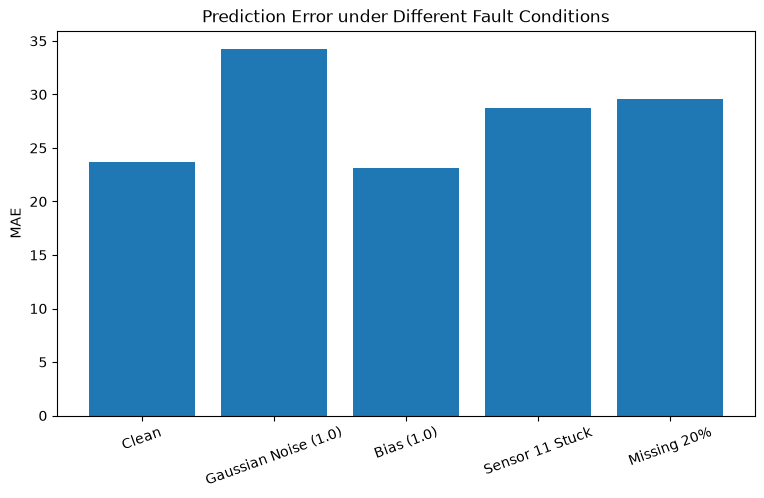

In [139]:
plt.figure(figsize=(9, 5))

plt.bar(
    ensemble_fault_results["Condition"],
    ensemble_fault_results["MAE"]
)

plt.ylabel("MAE")
plt.title("Prediction Error under Different Fault Conditions")
plt.xticks(rotation=20)

plt.show()

In [144]:
clean_mae = ensemble_fault_results.loc[
    ensemble_fault_results["Condition"]=="Clean",
    "MAE"
].values[0]


ensemble_fault_results["Performance_Drop(%)"] = (
    ensemble_fault_results["MAE"] - clean_mae
) / clean_mae * 100


ensemble_fault_results

,Condition,MAE,RMSE,Mean_Uncertainty,Performance_Drop(%)
0,Clean,23.665031,33.406113,2.368722,0.000000
1,Gaussian Noise (1.0),34.255119,43.820156,6.205927,44.749942
2,Bias (1.0),23.154335,29.621342,6.099011,-2.158021
3,Sensor 11 Stuck,28.693874,35.566545,2.658221,21.250100
4,Missing 20%,29.585030,39.812512,6.157837,25.015805


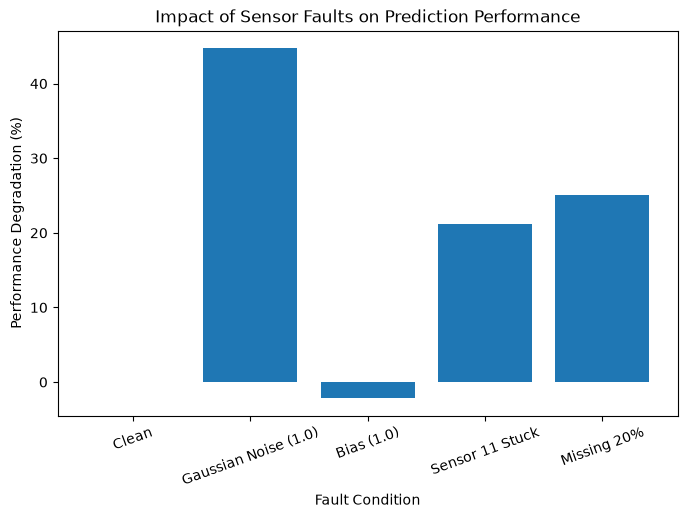

In [145]:
plt.figure(figsize=(8,5))

plt.bar(
    ensemble_fault_results["Condition"],
    ensemble_fault_results["Performance_Drop(%)"]
)

plt.ylabel(
    "Performance Degradation (%)"
)

plt.xlabel(
    "Fault Condition"
)

plt.title(
    "Impact of Sensor Faults on Prediction Performance"
)

plt.xticks(rotation=20)

plt.show()

### 初步模型验证结果（未对齐评价样本）

本表汇总随机森林、XGBoost和LSTM模型各自的初步验证结果。

需要注意，随机森林和XGBoost使用完整验证集进行评价，而LSTM采用长度为30的滑动窗口，有效评价样本数量较少，因此本表不作为三模型公平性能比较的依据。

正式的模型性能比较以 `fair_model_results` 和 `test_model_results` 为准。

In [148]:
model_results = pd.DataFrame({

    "Model":[
        "Random Forest",
        "XGBoost",
        "LSTM"
    ],

    "MAE":[
        rf_mae,
        xgb_mae,
        lstm_mae
    ],

    "RMSE":[
        rf_rmse,
        xgb_rmse,
        lstm_rmse
    ]

})


model_results

,Model,MAE,RMSE
0,Random Forest,25.879071,35.407605
1,XGBoost,25.714445,35.224112
2,LSTM,19.204477,27.708951


## 12. 实验结果可视化

对实验结果进行整理与可视化，包括：

- 三种模型的MAE和RMSE对比；
- XGBoost真实RUL与预测RUL的关系；
- 不同传感器故障下的预测误差变化；
- 预测不确定性及其与误差之间的关系。

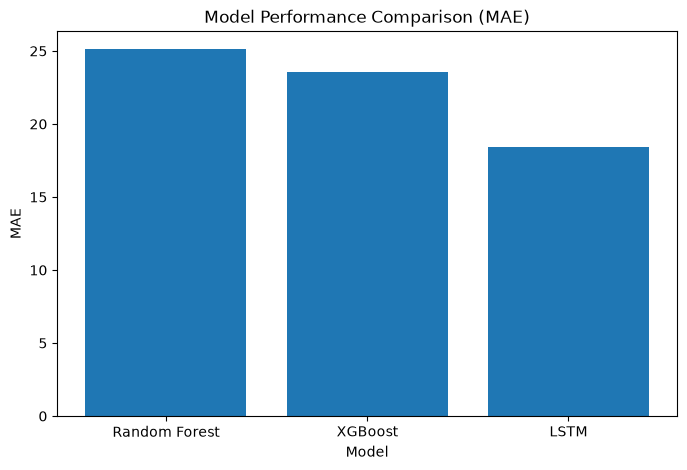

In [149]:
plt.figure(figsize=(8,5))


plt.bar(
    test_model_results["Model"],
    test_model_results["MAE"]
)


plt.xlabel("Model")

plt.ylabel("MAE")


plt.title(
    "Model Performance Comparison (MAE)"
)

plt.savefig(
    RESULTS_DIR / "model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

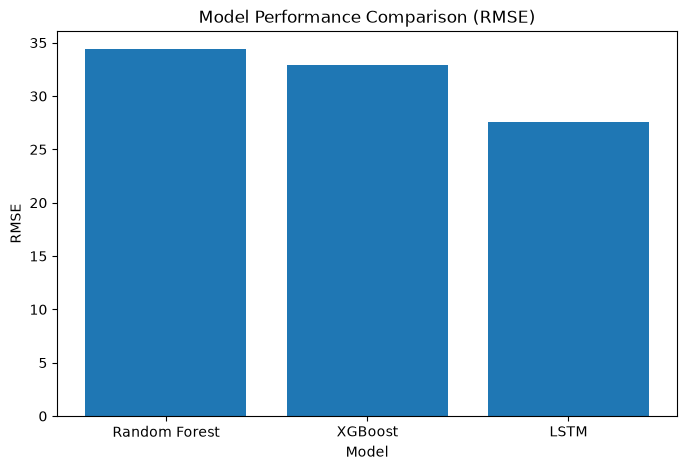

In [150]:
plt.figure(figsize=(8,5))


plt.bar(
    test_model_results["Model"],
    test_model_results["RMSE"]
)


plt.xlabel("Model")

plt.ylabel("RMSE")


plt.title(
    "Model Performance Comparison (RMSE)"
)


plt.savefig(
    RESULTS_DIR / "model_rmse_comparison.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

In [151]:
print(y_val.shape)
print(y_pred_xgb.shape)

(4070,)
(4070,)


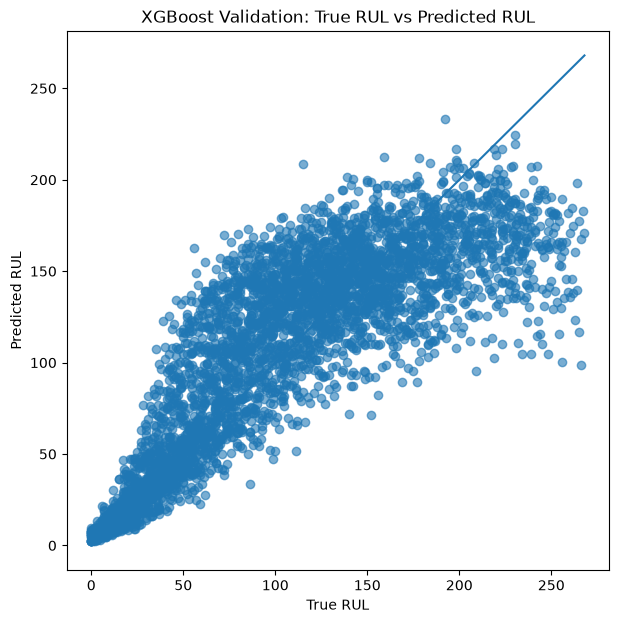

In [152]:
plt.figure(figsize=(7,7))


plt.scatter(
    y_val,
    y_pred_xgb,
    alpha=0.6
)


plt.xlabel("True RUL")

plt.ylabel("Predicted RUL")


plt.title(
    "XGBoost Validation: True RUL vs Predicted RUL"
)


# 理想预测线
plt.plot(
    [0, max(y_val)],
    [0, max(y_val)]
)


plt.savefig(
    RESULTS_DIR / "RUL_prediction.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

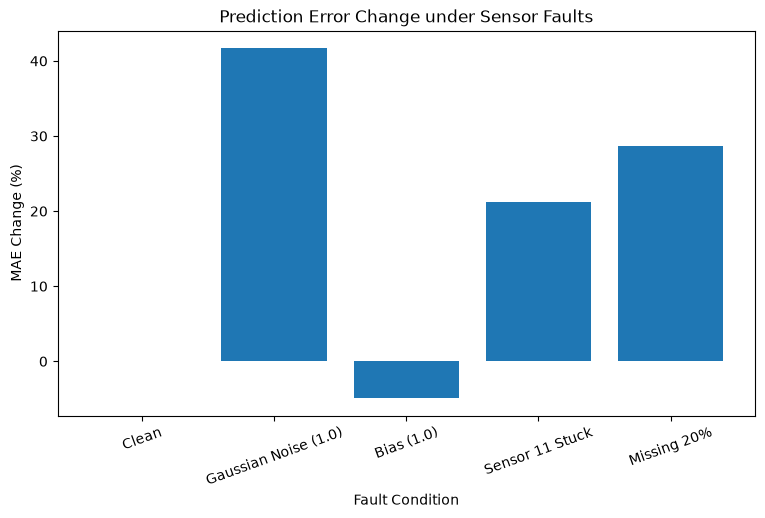

In [153]:
# 取得正常状态下的MAE
clean_mae = robustness_summary.loc[
    robustness_summary["Condition"] == "Clean",
    "MAE"
].iloc[0]

# 计算故障条件下的MAE变化率
robustness_summary["MAE_Change(%)"] = (
    (robustness_summary["MAE"] - clean_mae)
    / clean_mae * 100
)

# 绘图
plt.figure(figsize=(9, 5))

plt.bar(
    robustness_summary["Condition"],
    robustness_summary["MAE_Change(%)"]
)

plt.xlabel("Fault Condition")
plt.ylabel("MAE Change (%)")

plt.title(
    "Prediction Error Change under Sensor Faults"
)

plt.xticks(rotation=20)

# 保存图片
plt.savefig(
    RESULTS_DIR / "fault_impact.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 保存包含变化率的数据
robustness_summary.to_csv(
    RESULTS_DIR / "fault_performance_drop.csv",
    index=False
)

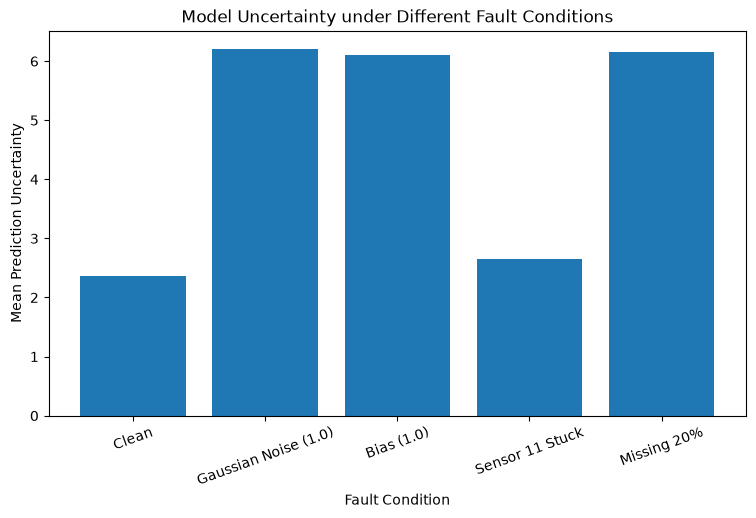

In [154]:
plt.figure(figsize=(9,5))


plt.bar(
    ensemble_fault_results["Condition"],
    ensemble_fault_results["Mean_Uncertainty"]
)


plt.xlabel("Fault Condition")

plt.ylabel(
    "Mean Prediction Uncertainty"
)


plt.title(
    "Model Uncertainty under Different Fault Conditions"
)


plt.xticks(rotation=20)


plt.savefig(
    RESULTS_DIR / "uncertainty_fault.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

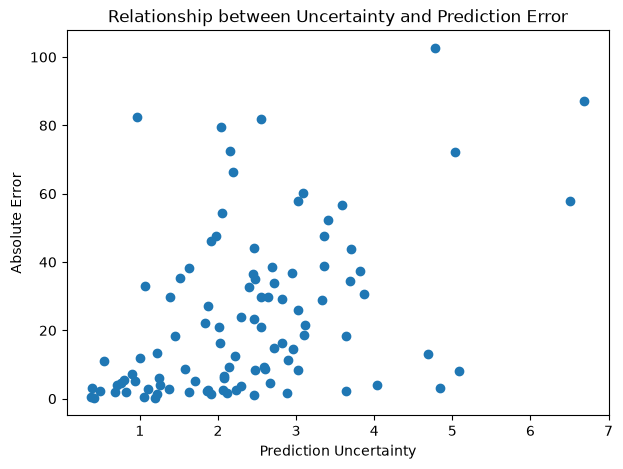

In [155]:
plt.figure(figsize=(7,5))


plt.scatter(
    uncertainty_error_df["Uncertainty"],
    uncertainty_error_df["Absolute_Error"]
)


plt.xlabel(
    "Prediction Uncertainty"
)

plt.ylabel(
    "Absolute Error"
)


plt.title(
    "Relationship between Uncertainty and Prediction Error"
)


plt.savefig(
    RESULTS_DIR / "uncertainty_error.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

In [156]:
fair_model_results

,Model,MAE,RMSE
0,Random Forest,23.476072,32.031207
1,XGBoost,23.259352,31.614462
2,LSTM,19.204477,27.708951


## 13. 实验总结与后续工作

本项目基于NASA C-MAPSS FD001数据集，构建随机森林、XGBoost和LSTM剩余寿命预测模型，并从预测精度、故障鲁棒性和不确定性三个方面开展可靠性分析。

### 主要成果

1. **RUL预测：** 完成三种预测模型的训练、验证及官方测试集性能比较。
2. **异常检测：** 实现数据缺失与Sensor 11连续卡死检测，卡死事件检出率达到100%，平均检测延迟为2.98个运行周期。
3. **异常修复：** 采用历史值填补和随机森林传感器估计方法，减轻异常数据对RUL预测性能的影响。
4. **稳定性验证：** 在5组随机种子实验中，历史值填补的平均MAE恢复率为92.09%，中位数填补的平均恢复率为-3.90%。

### 后续工作

进一步考虑不同故障强度、卡死持续时间和传感器类型对检测及修复效果的影响，完善智能预测模型可靠性评价体系。